[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/farrelrassya/Build-a-Large-Language-Model-From-Scratch/blob/main/05.Pretraining_On_Unlabeled_Data.ipynb)

# Chapter 5 -- Pretraining on Unlabeled Data

*Companion notebook untuk* Build a Large Language Model (From Scratch) *(Sebastian Raschka, Manning 2024)*
**Technical edition -- kode buku plus beberapa pengukuran tambahan**

Notebook ini berisi semua kode bab 5 dalam urutan buku, diambil dari repo resmi [`rasbt/LLMs-from-scratch`](https://github.com/rasbt/LLMs-from-scratch) (Apache-2.0). Di beberapa titik ada pengukuran tambahan yang tidak ada di buku, untuk menjawab pertanyaan "kenapa hasilnya begitu?". Bagian-bagian itu diberi judul **Under the hood** dan boleh dilewati kalau hanya ingin mengikuti materi buku. Sel kode tambahan lain ditandai komentar "Sel tambahan" di baris pertamanya.

| Under the hood | Yang kita ukur | Hasil |
|---|---|---|
| 1. Model acak vs tebakan uniform | Apakah model yang belum dilatih setidaknya sebaik menebak semua token dengan peluang sama | Tidak: loss 10.9876, di atas `ln 50257` = 10.8249, dan kelebihannya bisa dihitung dari varian logit |
| 2. Meteran hafalan | Berapa banyak teks hasil generate yang tersalin utuh dari data training, per strategi decoding | Greedy 89%, pengaturan buku (T = 1.4, top-25) 11%, teks validation asli 0% |
| 3. Checkpoint tanpa TensorFlow | Apakah checkpoint GPT-2 dari OpenAI bisa dibaca dengan NumPy saja | Bisa: 148 tensor sama byte demi byte dengan hasil TensorFlow |
| 4. Weight tying | Apakah embedding input dan lapisan output benar-benar memakai satu matriks setelah Listing 5.5 | Tidak: 163,037,184 parameter, bukan 124,439,808, dan keduanya sudah berbeda setelah satu langkah training |

Di akhir Chapter 4 kita punya GPT yang lengkap: embedding, dua belas blok transformer, dan lapisan output yang memberi skor untuk setiap token di kosakata. Tapi bobotnya masih acak, dan teks yang dihasilkannya kacau. Bab ini mengajarinya menulis. Caranya disebut *pretraining*: model membaca teks biasa sambil terus menebak token berikutnya, dan setiap kali tebakannya meleset, bobotnya digeser sedikit supaya tebakan berikutnya lebih baik. Data seperti ini tidak perlu diberi label oleh siapa pun, karena jawaban untuk setiap tebakan sudah tertulis di teks itu sendiri.

Kalimat "Every effort moves you" akan menemani kita sepanjang bab. Model acak melanjutkannya dengan potongan token tanpa arti. Model yang sedang dilatih melanjutkannya dengan deretan koma, lalu "and, and, and", lalu kalimat utuh dari cerpen yang dipakai sebagai data -- terlalu utuh, karena ternyata disalin. Kalimat yang sama kemudian dilanjutkan dengan cara memilih token yang lebih beragam, dan akhirnya dengan bobot GPT-2 asli dari OpenAI.

Untuk sampai ke sana kita butuh satu angka yang menilai seberapa buruk tebakan model, sebuah loop training, cara memilih token yang tidak selalu sama, cara menyimpan dan memuat bobot, dan cara memasang bobot OpenAI ke arsitektur buatan sendiri. Di sepanjang jalan ada satu pelajaran yang terus muncul: loss yang turun di data training belum tentu berarti model memahami bahasa. Bisa jadi ia hanya menghafal.

## Setup

Seluruh notebook ini bisa berjalan di CPU. Output yang tersimpan berasal dari satu run di Mac Apple Silicon (macOS arm64) dengan Python 3.14.6 dan torch 2.14.1, seperti tercetak di sel-sel awal.

Sel pertama memasang paket yang belum ada (`torch`, `tiktoken`, `matplotlib`, `numpy`, `requests`, `tqdm`, `safetensors`), lalu mengunduh empat file pendamping dari repo resmi pada satu commit tertentu dan mencocokkan sidik jari SHA-256 masing-masing. `previous_chapters.py` berisi `GPTModel` dan data loader dari Chapter 2 sampai 4; `gpt_download.py`, `gpt_train.py`, dan `gpt_generate.py` dipakai di 5.5 dan di bagian latihan.

Unduhan lain terjadi di tempatnya masing-masing: teks *The Verdict* (sekitar 20 KB) di 5.1.3, checkpoint GPT-2 124M (sekitar 500 MB) di 5.5, dan file bobot dari Hugging Face di Exercise 5.6. Di Exercise 5.6, GPT-2 medium dan large hanya dipakai kalau file-nya sudah ada di cache lokal (`EX56_LARGER = "auto"`), dan sel untuk GPT-2 XL dimatikan (`RUN_GPT2_XL = False`). Keduanya dibahas di bagian itu. Exercise 5.6 juga bagian yang paling berat untuk memori. Menurut hitungan di bagian itu, memuat GPT-2 774M butuh sekitar 6.6 GB RAM di puncaknya, sedangkan GPT-2 XL, yang dimatikan tadi, diperkirakan butuh sekitar 13 GB.

Buku memakai TensorFlow hanya untuk membaca checkpoint GPT-2 dari OpenAI, dan sel pertama sengaja tidak memasangnya. Kalau TensorFlow tidak ada, sel kode keempat, yang terakhir di Setup, menyediakan pembaca checkpoint pengganti yang hanya memakai NumPy; kalau ada, TensorFlow asli yang dipakai. Untuk memasang TensorFlow sendiri, pakai tanda kutip: `pip install "tensorflow>=2.15.0" "tqdm>=4.66"`. Alasannya dibahas di 5.5.

In [1]:
# Sel tambahan: dependensi + file pendamping companion repo (dipin ke commit, dicek SHA-256)
import hashlib, importlib.util, os, subprocess, sys

required = {"torch": "torch", "tiktoken": "tiktoken", "matplotlib": "matplotlib",
            "numpy": "numpy", "requests": "requests", "tqdm": "tqdm", "safetensors": "safetensors"}
missing = [pip for mod, pip in required.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import requests

COMMIT = "cdbd33e6d57a71e20ea31434841095fac50cecd8"
BASE = f"https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/{COMMIT}/ch05/01_main-chapter-code"
SHA256 = {
    "previous_chapters.py": "d611a73cb4e6eaeb8f46e18e9bcdb56d3b9d24f5db037300c73ac23973ec7e6f",
    "gpt_download.py": "3e2e95f7c3bf188e16e33e23fc9f0b1d285da55931f15fe12174d32cf10ec076",
    "gpt_train.py": "54623631dd9e9d50f7be63df4fd83220431815e3001f6b7b8750b2b03984ec59",
    "gpt_generate.py": "c3bbfe9463f81cc65962c561d9b2bc9b9af11f623d13df1a9c0ef608a507ed7b",
}
for fname, digest in SHA256.items():
    if not os.path.exists(fname):
        r = requests.get(f"{BASE}/{fname}", timeout=60)
        r.raise_for_status()
        with open(fname, "wb") as f:
            f.write(r.content)
    got = hashlib.sha256(open(fname, "rb").read()).hexdigest()
    print(f"{fname:<22} sha256 {got[:16]}  {'ok' if got == digest else 'BEDA dari commit yang dipin'}")
print("python    :", sys.version.split()[0])
print("dipasang  :", ", ".join(missing) if missing else "tidak ada (semua sudah terpasang)")
print("tensorflow:", "terpasang" if importlib.util.find_spec("tensorflow") else "tidak terpasang (pembaca NumPy akan dipakai)")

previous_chapters.py   sha256 d611a73cb4e6eaeb  ok
gpt_download.py        sha256 3e2e95f7c3bf188e  ok
gpt_train.py           sha256 54623631dd9e9d50  ok
gpt_generate.py        sha256 c3bbfe9463f81cc6  ok
python    : 3.14.6
dipasang  : tidak ada (semua sudah terpasang)
tensorflow: terpasang


Keempat file pendamping cocok dengan isi repo pada commit `cdbd33e` (tanda `ok` di setiap baris), dan tidak ada paket yang perlu dipasang. TensorFlow ternyata sudah terpasang di lingkungan run ini, jadi bagian 5.5 akan memakai TensorFlow asli. File `the-verdict.txt` sengaja tidak diunduh di sini, karena sel dari repo di 5.1.3 mengunduhnya sendiri sebagai bagian dari listing bab.

Sel berikut adalah sel versi paket dari repo, dibungkus `try/except` supaya di lingkungan tanpa TensorFlow error-nya hanya tercetak tanpa menghentikan notebook.

In [2]:
# Sel repo [2] verbatim, dibungkus try/except supaya Run all tidak berhenti bila TensorFlow tidak terpasang
import traceback

try:
    from importlib.metadata import version
    
    pkgs = ["matplotlib", 
            "numpy", 
            "tiktoken", 
            "torch",
            "tensorflow" # For OpenAI's pretrained weights
           ]
    for p in pkgs:
        print(f"{p} version: {version(p)}")
except Exception:
    traceback.print_exc()

matplotlib version: 3.11.2
numpy version: 2.5.4
tiktoken version: 0.14.0
torch version: 2.14.1
tensorflow version: 2.22.0rc0


Versi-versi ini jauh lebih baru daripada saat buku ditulis; notebook resmi dari masa itu memakai torch 2.4.0 dan tiktoken 0.7.0. Apakah hasilnya masih sama dengan buku? Itu akan kita periksa di beberapa titik, terutama di log training 5.2.

Ada satu hal yang ganjil: TensorFlow yang terpasang adalah `2.22.0rc0`, sebuah *release candidate* (versi uji sebelum rilis), bukan rilis stabil. Sel berikut bertanya langsung ke pip dengan `--dry-run`, tanpa memasang apa pun: versi apa yang ia pilih untuk requirement buku `tensorflow>=2.15.0`, dan apa yang tersisa kalau release candidate dikecualikan.

In [3]:
# Sel tambahan: catatan versi -- apa yang dipilih resolver pip untuk requirement buku (dry-run, tanpa instalasi)
import json, os, subprocess, sys, sysconfig, tempfile

print("interpreter:", sys.version.split()[0], "| tag wheel:", f"cp{sys.version_info.major}{sys.version_info.minor}", "|", sysconfig.get_platform())
pip = [sys.executable, "-m", "pip", "install", "--dry-run", "--ignore-installed", "--no-deps", "--no-color"]   # kernel Jupyter memicu warna ANSI
with tempfile.TemporaryDirectory() as tmp:   # laporan ke file: di kernel, stdout pip diformat ulang oleh rich
    report = os.path.join(tmp, "report.json")
    r = subprocess.run(pip + ["--quiet", "--report", report, "tensorflow>=2.15.0"], capture_output=True, text=True)
    try:
        pick = json.load(open(report))["install"][0]
        print("requirement buku 'tensorflow>=2.15.0' ->", pick["metadata"]["version"], "|", pick["download_info"]["url"].rsplit("/", 1)[-1])
    except (OSError, ValueError, KeyError, IndexError):   # jaringan/PyPI gagal: laporkan, jangan hentikan Run all
        print("requirement buku 'tensorflow>=2.15.0' -> resolver gagal:", (r.stderr.strip().splitlines() or ["tanpa pesan"])[-1])
r = subprocess.run(pip + ["tensorflow>=2.15.0,<2.22"], capture_output=True, text=True)
err = [l for l in r.stderr.splitlines() if l.startswith("ERROR: Could not find")]
print("tanpa release candidate ('<2.22')      ->", err[0] if err else f"exit {r.returncode}, tanpa pesan 'Could not find'")

interpreter: 3.14.6 | tag wheel: cp314 | macosx-26.0-arm64
requirement buku 'tensorflow>=2.15.0' -> 2.22.0rc0 | tensorflow-2.22.0rc0-cp314-cp314-macosx_12_0_arm64.whl
tanpa release candidate ('<2.22')      -> ERROR: Could not find a version that satisfies the requirement tensorflow<2.22,>=2.15.0 (from versions: 2.22.0rc0)


Pip memilih `2.22.0rc0`, dan tanpa release candidate tidak ada satu versi pun yang tersedia untuk Python 3.14 di Mac ini. Biasanya pip mengabaikan versi pre-release, tapi aturan PEP 440 punya pengecualian: kalau hanya pre-release yang memenuhi requirement, pre-release itulah yang dipasang. Jadi `pip install "tensorflow>=2.15.0"` di Python 3.14 di Mac ini diam-diam memasang versi yang belum stabil. Untuk bab ini dampaknya kecil, karena TensorFlow hanya dipakai untuk membaca file checkpoint.

Ketergantungan pada TensorFlow itu memang tipis. `gpt_download.py` hanya memanggil tiga fungsi: `tf.train.latest_checkpoint`, `tf.train.list_variables`, dan `tf.train.load_variable`. Ketiganya membaca checkpoint TensorFlow yang terdiri dari dua file. File `.index` adalah tabel kunci-nilai berformat SSTable, format tabel terurut yang juga dipakai LevelDB, yang mencatat nama, bentuk, dan posisi setiap tensor. File `.data-00000-of-00001` berisi byte mentah semua tensor. Sel berikut menulis ulang ketiga fungsi itu dengan NumPy dan mendaftarkannya sebagai modul `tensorflow`, tapi hanya kalau TensorFlow tidak terpasang. Dengan begitu `gpt_download.py` dan `gpt_generate.py` dari repo bisa berjalan tanpa diubah, baik dengan maupun tanpa TensorFlow.

In [4]:
# Sel tambahan: pembaca checkpoint TensorFlow V2 dengan NumPy saja (pengganti tf.train untuk gpt_download.py)
# Format: model.ckpt.index = SSTable (kunci = nama variabel, nilai = BundleEntryProto: dtype, shape,
# shard, offset, size, crc32c); model.ckpt.data-00000-of-00001 = byte tensor mentah little-endian.
import importlib.util, os, re, sys, types
from functools import lru_cache
from pathlib import Path
import numpy as np

MAGIC = 0xDB4775248B80FB57                                   # last 8 bytes of every SSTable
DTYPES = {1: "<f4", 2: "<f8", 3: "<i4", 9: "<i8", 19: "<f2"}  # TF DataType enum -> NumPy

def _varint(buf, pos):  # base-128 varint (protobuf and LevelDB) -> (value, next_pos)
    value = shift = 0
    while buf[pos] & 0x80:                                    # high bit set: more bytes follow
        value |= (buf[pos] & 0x7F) << shift
        pos, shift = pos + 1, shift + 7
    return value | buf[pos] << shift, pos + 1

def _proto(buf):  # minimal protobuf decoder -> {field_number: [int or bytes values]}
    fields, pos = {}, 0
    while pos < len(buf):
        tag, pos = _varint(buf, pos)                          # tag = field_number << 3 | wire type
        if tag & 7 == 0:                                      # varint
            value, pos = _varint(buf, pos)
        elif tag & 7 == 2:                                    # length-delimited (sub-message)
            n, pos = _varint(buf, pos)
            value, pos = buf[pos:pos + n], pos + n
        elif tag & 7 == 5:                                    # fixed32 (the crc32c field)
            value, pos = int.from_bytes(buf[pos:pos + 4], "little"), pos + 4
        else:
            raise ValueError(f"unsupported protobuf wire type {tag & 7}")
        fields.setdefault(tag >> 3, []).append(value)
    return fields

def _block(data, handle, pos=0):  # (key, value) pairs of the block a BlockHandle points to
    offset, pos = _varint(handle, pos)
    size, _ = _varint(handle, pos)
    if data[offset + size] != 0:                              # trailer byte 0 = no compression
        raise NotImplementedError(f"compressed SSTable block (type {data[offset + size]})")
    block = data[offset:offset + size]
    end = size - 4 - 4 * int.from_bytes(block[-4:], "little")  # restart array: n x uint32 + n
    pos, key, entries = 0, b"", []
    while pos < end:
        shared, pos = _varint(block, pos)
        unshared, pos = _varint(block, pos)
        n_value, pos = _varint(block, pos)
        key = key[:shared] + block[pos:pos + unshared]        # undo shared-prefix compression
        entries.append((key, block[pos + unshared:pos + unshared + n_value]))
        pos += unshared + n_value
    return entries

@lru_cache(maxsize=8)
def _index(prefix, mtime_ns):  # -> (num_shards, {name: entry}); mtime_ns invalidates cache
    data = Path(prefix + ".index").read_bytes()
    footer = data[-48:]
    if int.from_bytes(footer[-8:], "little") != MAGIC:
        raise ValueError(f"{prefix}.index is not an SSTable (bad magic number)")
    pos = _varint(footer, _varint(footer, 0)[1])[1]           # skip metaindex handle (unused)
    raw = {k.decode(): v for _, h in _block(data, footer, pos) for k, v in _block(data, h)
           if b"\x00" not in k}                               # skip slice keys of partitioned vars
    header = _proto(raw.pop(""))                              # key "" = BundleHeaderProto
    if header.get(2, [0])[0] != 0:                            # field 2 = endianness, 0 = LITTLE
        raise NotImplementedError(f"{prefix}: big-endian tensor bundle")
    entries = {}
    for name, value in raw.items():                           # BundleEntryProto; proto3 omits 0s
        f = {k: v[0] for k, v in _proto(value).items()}
        dims = _proto(f.get(2, b"")).get(2, [])               # TensorShapeProto.dim[]
        entries[name] = dict(dtype=f.get(1, 0), shape=[_proto(d).get(1, [0])[0] for d in dims],
                             shard_id=f.get(3, 0), offset=f.get(4, 0), size=f.get(5, 0),
                             crc32c=f.get(6), sliced=7 in f)  # 7 = TensorSliceProto (partitioned)
    return header.get(1, [1])[0], entries

def _open(path):  # checkpoint dir or prefix -> (prefix, num_shards, entries)
    prefix = latest_checkpoint(path) if os.path.isdir(path) else path
    if prefix is None:
        raise FileNotFoundError(f"no checkpoint found in {path}")
    return prefix, *_index(prefix, os.stat(prefix + ".index").st_mtime_ns)

@lru_cache(maxsize=16)
def _shard(path, mtime_ns):  # one read-only byte map per data file (= one file descriptor)
    return np.memmap(path, np.uint8, mode="r")

def latest_checkpoint(checkpoint_dir):
    """Prefix named by model_checkpoint_path in checkpoint_dir/checkpoint, or None."""
    state = Path(checkpoint_dir, "checkpoint")
    text = state.read_text(encoding="utf-8") if state.exists() else ""
    match = re.search(r'^model_checkpoint_path:\s*"(.*)"', text, re.M)
    prefix = match and os.path.join(checkpoint_dir, match.group(1))  # relative to the dir
    return prefix if prefix and os.path.exists(prefix + ".index") else None

def list_variables(ckpt_dir_or_file):
    """[(name, shape)] sorted by name, like tf.train.list_variables."""
    entries = _open(ckpt_dir_or_file)[2]
    return [(name, entries[name]["shape"]) for name in sorted(entries)]

def load_variable(ckpt_dir_or_file, name):
    """Tensor `name` as a read-only NumPy array: a zero-copy view into the data file."""
    prefix, num_shards, entries = _open(ckpt_dir_or_file)
    e = entries[name.removesuffix(":0")]
    if e["dtype"] not in DTYPES or e["sliced"]:
        raise NotImplementedError(f"{name}: TF dtype enum {e['dtype']}, sliced={e['sliced']}")
    dtype, shape = np.dtype(DTYPES[e["dtype"]]), tuple(e["shape"])
    if e["size"] != dtype.itemsize * np.prod(shape, dtype=np.int64):
        raise ValueError(f"{name}: {e['size']} bytes do not match shape {shape}")
    shard = f"{prefix}.data-{e['shard_id']:05d}-of-{num_shards:05d}"
    raw = _shard(shard, os.stat(shard).st_mtime_ns)[e["offset"]:e["offset"] + e["size"]]
    return np.asarray(raw).view(dtype).reshape(shape)

def install_as_tensorflow():
    """Register a module "tensorflow" exposing .train.* -- only if TensorFlow is absent."""
    if "tensorflow" in sys.modules or importlib.util.find_spec("tensorflow") is not None:
        return importlib.import_module("tensorflow")          # an existing / real TF wins
    tf = types.ModuleType("tensorflow", "NumPy-only tf.train checkpoint reader (NOT TensorFlow)")
    tf.IS_NUMPY_SHIM = True
    tf.train = types.SimpleNamespace(latest_checkpoint=latest_checkpoint,
                                     list_variables=list_variables, load_variable=load_variable)
    sys.modules["tensorflow"] = tf
    return tf


tf = install_as_tensorflow()
print("modul 'tensorflow' aktif:", "pengganti NumPy (TensorFlow tidak terpasang)" if getattr(tf, "IS_NUMPY_SHIM", False)
      else f"TensorFlow asli {tf.__version__}")

modul 'tensorflow' aktif: TensorFlow asli 2.22.0-rc0


Karena TensorFlow asli terpasang, `install_as_tensorflow()` tidak mendaftarkan apa pun dan hanya mengembalikan modul TensorFlow itu sendiri. Fungsi-fungsi NumPy-nya tetap terdefinisi, dan di Under the hood 3 kita akan memakainya untuk membandingkan isi checkpoint dengan TensorFlow, tensor demi tensor. Di lingkungan tanpa TensorFlow perannya bertukar: `import tensorflow` di `gpt_download.py` akan mendapat modul pengganti ini.

Ada dua keputusan desain di kode itu. Yang pertama soal memori. Tensor dikembalikan sebagai *view* read-only ke sebuah *memory map*, yaitu file yang dipetakan langsung ke memori, sehingga memuat bobot tidak menyalin ratusan MB ke RAM sebelum nilainya benar-benar dipakai. Setiap file data hanya dipetakan sekali, bukan sekali per tensor. Alasannya, setiap memory map menahan satu *file descriptor*, yaitu penanda yang diberikan sistem operasi untuk setiap file yang sedang terbuka, dan jumlahnya dibatasi; di macOS batas bawaannya biasanya 256. Checkpoint GPT-2 yang lebih besar berisi ratusan tensor, jadi satu memory map per tensor akan menabrak batas itu dengan error *Too many open files*.

Yang kedua soal kegagalan. Kalau checkpoint memakai fitur yang tidak didukung -- kompresi blok, tipe data selain float dan int, atau variabel yang dipecah -- fungsi ini berhenti dengan error yang jelas alih-alih diam-diam membaca byte yang salah.

## 5.1 Evaluating generative text models

Dalam peta tiga tahap buku, bab ini mengerjakan tahap kedua: pretraining, yaitu melatih model yang arsitekturnya sudah lengkap tapi bobotnya masih acak menjadi *foundation model* yang mengenal pola bahasa. Sebelum loop training bisa ditulis, kita perlu tiga hal: cara bolak-balik antara teks dan token, satu angka yang mengukur seberapa buruk tebakan model, dan angka itu dihitung di seluruh dataset. Ketiganya dikerjakan di 5.1.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.1.png" width="700">

**Figure 5.1** Tiga tahap membangun LLM. Bab ini mengerjakan tahap 2: loop training, evaluasi model, serta menyimpan dan memuat bobot, termasuk bobot pretrained dari OpenAI.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.2.png" width="700">

**Figure 5.2** Tujuh topik bab ini. Tiga yang pertama -- menghasilkan teks, mengevaluasi teks, dan menghitung loss training dan validation -- dikerjakan di 5.1.

### 5.1.1 Using GPT to generate text

Kita mulai dengan menyiapkan model yang sama seperti di Chapter 4, lalu memintanya melanjutkan sebuah kalimat. Satu istilah perlu disepakati dulu. *Weights* atau bobot di bab ini berarti semua parameter yang diubah oleh training: matriks di dalam `nn.Linear` dan `nn.Embedding`, ditambah bias dan parameter LayerNorm. PyTorch mengumpulkan semuanya lewat `model.parameters()`, dan kumpulan itulah yang nanti diserahkan ke optimizer.

Konfigurasinya sama dengan Chapter 4 kecuali satu hal: `context_length` dipangkas dari 1,024 menjadi 256 token, supaya training cukup ringan untuk laptop. Hampir semua parameter tidak berubah; yang menyusut hanya tabel positional embedding (`256 x 768` alih-alih `1024 x 768`). Penghematan yang terasa ada di komputasi, karena attention kini hanya bekerja pada urutan 256 token. Dropout tetap 0.1, walaupun buku mencatat bahwa LLM modern sering dilatih tanpa dropout.

In [5]:
import torch
from previous_chapters import GPTModel
# If the `previous_chapters.py` file is not available locally,
# you can import it from the `llms-from-scratch` PyPI package.
# For details, see: https://github.com/rasbt/LLMs-from-scratch/tree/main/pkg
# E.g.,
# from llms_from_scratch.ch04 import GPTModel

GPT_CONFIG_124M = {
    "vocab_size": 50257,   # Vocabulary size
    "context_length": 256, # Shortened context length (orig: 1024)
    "emb_dim": 768,        # Embedding dimension
    "n_heads": 12,         # Number of attention heads
    "n_layers": 12,        # Number of layers
    "drop_rate": 0.1,      # Dropout rate
    "qkv_bias": False      # Query-key-value bias
}

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.eval();  # Disable dropout during inference

Dua fungsi kecil berikut menutup siklus dari teks ke token ID, ke logits, kembali ke token ID, lalu ke teks. `text_to_token_ids` mengubah teks menjadi tensor dan menambahkan dimensi batch, karena model selalu menerima batch; `token_ids_to_text` membuang dimensi itu lagi sebelum decode. Seed 123 di sel sebelumnya menentukan bobot acak model, jadi sepuluh token yang dihasilkan secara greedy di bawah bisa dibandingkan dengan buku.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.3.png" width="700">

**Figure 5.3** Siklus tiga langkah: tokenizer mengubah teks menjadi token ID, model menghasilkan satu vektor logit berisi 50,257 angka untuk setiap posisi, lalu logit itu diubah kembali menjadi token ID dan teks.

In [6]:
import tiktoken
from previous_chapters import generate_text_simple

# Alternatively:
# from llms_from_scratch.ch04 import generate_text_simple

def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={'<|endoftext|>'})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) # add batch dimension
    return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0) # remove batch dimension
    return tokenizer.decode(flat.tolist())

start_context = "Every effort moves you"
tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=10,
    context_size=GPT_CONFIG_124M["context_length"]
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you rentingetic wasnم refres RexMeCHicular stren


Model menulis `Every effort moves you rentingetic wasnم refres RexMeCHicular stren`. Kacau, seperti yang diharapkan dari bobot acak, dan sama dengan buku token demi token. Satu-satunya beda ada di tampilan token ketiga: buku mencetak `wasn?`, padahal karakter aslinya huruf Arab `م`. Font di PDF buku tidak punya bentuk huruf itu dan menggantinya dengan tanda tanya.

Kenapa teks acak ini bisa sama persis dengan buku, padahal mesin dan versi PyTorch-nya berbeda? Bobot acak berasal dari generator bilangan acak yang diberi seed 123 dan dipanggil dalam urutan yang sama untuk setiap lapisan, dan argmax selalu memilih token yang sama selama logit-nya tidak bergeser terlalu jauh. Kecocokan ini berlaku di level token; ia tidak menjamin bobotnya sama sampai bit terakhir.

Teks ini jelas tidak koheren, tapi "tidak koheren" belum berupa angka. Untuk melatih model, kita butuh ukuran yang bisa dihitung dan diperkecil.

### 5.1.2 Calculating the text generation loss

Menghasilkan teks terdiri dari lima langkah: teks diubah menjadi token ID, model mengubah ID menjadi logits, softmax mengubah logits menjadi probabilitas, argmax memilih token dengan probabilitas tertinggi di setiap posisi, lalu ID dikembalikan menjadi teks. Loss memakai tiga langkah pertama yang sama. Bedanya, alih-alih bertanya token mana yang paling disukai model, loss bertanya berapa probabilitas yang diberikan model kepada token yang *seharusnya* muncul.

Sebagai contoh, kita pakai dua potongan kalimat yang masing-masing berisi tiga token, "every effort moves" dan "I really like". Target untuk setiap posisi adalah token berikutnya di kalimat, jadi target adalah input yang digeser satu posisi ke kanan -- skema *next-token prediction* yang sama dengan data loader di Chapter 2.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.4.png" width="700">

**Figure 5.4** Lima langkah menghasilkan teks, dengan kosakata mainan berisi tujuh kata: memetakan teks ke ID, menghitung softmax di setiap posisi, memilih ID dengan argmax, mengumpulkan ID terpilih, lalu memetakannya kembali ke teks.

In [7]:
inputs = torch.tensor([[16833, 3626, 6100],   # ["every effort moves",
                       [40,    1107, 588]])   #  "I really like"]

targets = torch.tensor([[3626, 6100, 345  ],  # [" effort moves you",
                        [1107,  588, 11311]]) #  " really like chocolate"]

In [8]:
with torch.no_grad():
    logits = model(inputs)

probas = torch.softmax(logits, dim=-1) # Probability of each token in vocabulary
print(probas.shape) # Shape: (batch_size, num_tokens, vocab_size)

torch.Size([2, 3, 50257])


Bentuk `(2, 3, 50257)` dibaca begini: 2 contoh, 3 posisi per contoh, dan di setiap posisi satu distribusi probabilitas atas 50,257 token kosakata. Buku menyebut dimensi terakhir ini *embedding dimensionality*, padahal yang diukurnya adalah ukuran kosakata. Dimensi embedding model ini 768, dan sudah diproyeksikan keluar oleh `out_head` (dari 768 ke 50,257). Membedakan keduanya penting: kode yang menganggap `probas.shape[-1]` sama dengan `emb_dim` akan gagal.

Sekarang kita lihat token apa yang akan dipilih model di setiap posisi.

In [9]:
token_ids = torch.argmax(probas, dim=-1, keepdim=True)
print("Token IDs:\n", token_ids)

Token IDs:
 tensor([[[16657],
         [  339],
         [42826]],

        [[49906],
         [29669],
         [41751]]])


Enam token ID terpilih: `[16657, 339, 42826]` untuk kalimat pertama dan `[49906, 29669, 41751]` untuk kalimat kedua. Bentuknya `(2, 3, 1)` karena `keepdim=True` mempertahankan dimensi terakhir. Semua angka di bagian ini, dari token ID ini sampai loss yang akan kita hitung, sama dengan yang dicetak buku sampai digit yang tampil, jadi kecocokan itu tidak perlu diulang di setiap langkah. Kita baru akan membahasnya lagi kalau kecocokan atau selisihnya mengajarkan sesuatu, seperti selisih satu bit di 5.1.3.

Kalau ID kalimat pertama di-decode, kita bisa melihat seberapa jauh tebakan model dari target.

In [10]:
print(f"Targets batch 1: {token_ids_to_text(targets[0], tokenizer)}")
print(f"Outputs batch 1: {token_ids_to_text(token_ids[0].flatten(), tokenizer)}")

Targets batch 1:  effort moves you
Outputs batch 1:  Armed heNetflix


Targetnya ` effort moves you`, sedangkan tebakan model ` Armed heNetflix`: tiga token yang sama sekali tidak berhubungan. Untuk model acak ini wajar, dan masalahnya bukan bahwa model "salah sedikit". Ia membagi probabilitas hampir rata ke lima puluh ribu token, sehingga token mana yang kebetulan menang hampir tidak ada artinya. Ukuran yang lebih berguna adalah berapa probabilitas yang jatuh ke token target, karena angka itulah yang ingin dinaikkan oleh training.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.5.png" width="700">

**Figure 5.5** Langkah 1, menghasilkan teks, sudah selesai. Langkah 2 adalah fungsi untuk mengevaluasi teks.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.6.png" width="700">

**Figure 5.6** Sebelum training, vektor probabilitas di setiap posisi hampir rata (sekitar 1/7 untuk kosakata tujuh kata). Tugas training adalah menaikkan probabilitas di indeks token target.

In [11]:
text_idx = 0
target_probas_1 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 1:", target_probas_1)

text_idx = 1
target_probas_2 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 2:", target_probas_2)

Text 1: tensor([7.4541e-05, 3.1061e-05, 1.1563e-05])
Text 2: tensor([1.0337e-05, 5.6776e-05, 4.7559e-06])


Keenam probabilitas target ini, dari `7.4541e-05` sampai `4.7559e-06`, perlu patokan supaya bisa dibaca. Bandingkan dengan *tebakan uniform*, yaitu memberi setiap token probabilitas yang sama, `1/50257`, sekitar `1.99e-05`. Target pertama kalimat pertama mendapat sekitar 3.75 kali probabilitas itu, sedangkan target terakhir kalimat kedua hanya sekitar 0.24 kali. Jadi model acak tidak benar-benar rata: ada token yang ia sukai tanpa alasan, dan target bisa jatuh di atas atau di bawah rata-rata. Fakta kecil ini akan menjadi penting di Under the hood 1.

Training ingin mendorong keenam angka ini ke arah 1. Mengalikan probabilitas sekecil ini secara langsung cepat menghasilkan angka yang terlalu kecil untuk disimpan float32, dan gradiennya pun sulit dioptimalkan. Karena itu yang dipakai adalah logaritmanya: perkalian berubah menjadi penjumlahan, dan angka-angkanya tetap berada di rentang yang wajar.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.7.png" width="700">

**Figure 5.7** Enam langkah menuju loss: logits, probabilitas, probabilitas target, logaritma, rata-rata, lalu negasi. Hasil akhirnya, negative average log probability, adalah 10.7940.

In [12]:
# Compute logarithm of all token probabilities
log_probas = torch.log(torch.cat((target_probas_1, target_probas_2)))
print(log_probas)

tensor([ -9.5042, -10.3796, -11.3677, -11.4798,  -9.7764, -12.2561])


Ini langkah keempat: enam log-probabilitas, dari `-9.5042` sampai `-12.2561`. Semuanya negatif karena setiap probabilitas lebih kecil dari 1, dan makin jauh dari 0, makin kecil probabilitas yang diberikan kepada target. Patokannya, log dari tebakan uniform, `ln(1/50257)`, adalah -10.8249; tiga dari enam angka di atas berada di atas patokan itu dan tiga di bawahnya.

In [13]:
# Calculate the average probability for each token
avg_log_probas = torch.mean(log_probas)
print(avg_log_probas)

tensor(-10.7940)


Langkah kelima: rata-ratanya `-10.7940`. Tujuan training bisa dirumuskan sebagai mendorong angka ini ke 0, yaitu titik ketika setiap token target mendapat probabilitas 1.

In [14]:
neg_avg_log_probas = avg_log_probas * -1
print(neg_avg_log_probas)

tensor(10.7940)


Langkah keenam hanya membalik tanda, menjadi `10.7940`. Alasannya konvensi: di deep learning, yang diminimalkan adalah loss, jadi yang dipakai adalah negatif dari rata-rata log-probabilitas.

Secara formal, untuk $N$ posisi dengan token target $y_i$ dan distribusi prediksi $q_i$:

$$\mathcal{L} = -\frac{1}{N}\sum_{i=1}^{N} \log q_i(y_i)$$

Besaran ini disebut *cross-entropy* antara distribusi data, yang seluruh probabilitasnya ada di token target, dan distribusi prediksi model. PyTorch menyediakan keenam langkah tadi dalam satu fungsi, `cross_entropy`, dengan dua syarat. Fungsi ini menerima *logits*, bukan probabilitas, karena softmax-nya dikerjakan di dalam. Dan ia menginginkan prediksi berbentuk 2D serta target berbentuk 1D. Mari periksa bentuk yang kita punya.

In [15]:
# Logits have shape (batch_size, num_tokens, vocab_size)
print("Logits shape:", logits.shape)

# Targets have shape (batch_size, num_tokens)
print("Targets shape:", targets.shape)

Logits shape: torch.Size([2, 3, 50257])
Targets shape: torch.Size([2, 3])


Logits berbentuk `(batch, token, kosakata)`, yaitu `(2, 3, 50257)`, sedangkan target berbentuk `(batch, token)`, yaitu `(2, 3)`. `cross_entropy` menginginkan deretan baris prediksi dengan satu indeks kelas per baris, jadi dimensi batch dan token perlu digabung.

In [16]:
logits_flat = logits.flatten(0, 1)
targets_flat = targets.flatten()

print("Flattened logits:", logits_flat.shape)
print("Flattened targets:", targets_flat.shape)

Flattened logits: torch.Size([6, 50257])
Flattened targets: torch.Size([6])


Sekarang ada enam baris prediksi, `(6, 50257)`, dan enam indeks target, `(6,)`. Satu panggilan fungsi akan menggantikan softmax, pengambilan probabilitas target, logaritma, rata-rata, dan negasi.

In [17]:
loss = torch.nn.functional.cross_entropy(logits_flat, targets_flat)
print(loss)

tensor(10.7940)


Hasilnya `10.7940`, sama dengan jalur manual sampai empat desimal yang tercetak. Walaupun hasilnya sama, cara menghitungnya berbeda, dan perbedaan itu berguna diketahui. `cross_entropy` tidak menghitung softmax lalu logaritma secara terpisah seperti jalur manual kita. Ia memakai `log_softmax`, yang mengurangkan logit terbesar sebelum menghitung eksponen dan tidak pernah membentuk probabilitas kecil itu secara eksplisit. Untuk probabilitas sekitar `1e-05` seperti di sini kedua jalur sepakat. Untuk logit yang sangat ekstrem, probabilitasnya bisa terlalu kecil untuk disimpan float32 dan dibulatkan menjadi nol, sehingga jalur manual menghasilkan `-inf`, sedangkan `cross_entropy` tetap memberi angka yang benar.

In [18]:
perplexity = torch.exp(loss)
print(perplexity)

tensor(48725.8203)


Perplexity adalah eksponen dari loss: `torch.exp(loss)` memberi `48725.8203`. Tafsiran populernya: model sama bingungnya dengan seseorang yang harus memilih secara acak di antara hampir 49 ribu token. Bandingkan dengan ukuran kosakata, 50,257: pada keenam token ini, model sedikit lebih baik daripada tebakan uniform.

Tafsiran ini enak dibaca, tapi diam-diam menganggap bahwa model yang tidak tahu apa-apa paling buruk setara tebakan uniform. Di akhir 5.1.3, saat loss dihitung di seluruh dataset, kita akan melihat bahwa anggapan itu tidak selalu benar.

### 5.1.3 Calculating the training and validation set losses

Loss tadi dihitung untuk dua kalimat mainan. Untuk melatih dan menilai model, angka yang sama perlu dihitung di seluruh dataset, yang dipisah menjadi data training dan data validation. Datanya adalah *The Verdict*, cerpen Edith Wharton yang sudah kita pakai di Chapter 2: domain publik, dan cukup kecil untuk dilatih di laptop dalam hitungan menit. Buku juga menyebut alternatif berskala besar, yaitu lebih dari 60,000 buku dari Project Gutenberg; kodenya ada di folder bonus `ch05/03_bonus_pretraining_on_gutenberg` di repo resmi.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.8.png" width="700">

**Figure 5.8** Setelah cross-entropy dihitung untuk satu batch kecil, loss yang sama diterapkan ke seluruh data training dan validation.

In [19]:
import os
import requests

file_path = "the-verdict.txt"
url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt"

if not os.path.exists(file_path):
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    text_data = response.text
    with open(file_path, "w", encoding="utf-8") as file:
        file.write(text_data)
else:
    with open(file_path, "r", encoding="utf-8") as file:
        text_data = file.read()


# The book originally used the following code below
# However, urllib uses older protocol settings that
# can cause problems for some readers using a VPN.
# The `requests` version above is more robust
# in that regard.

        
# import os
# import urllib.request

# file_path = "the-verdict.txt"
# url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt"

# if not os.path.exists(file_path):
#     with urllib.request.urlopen(url) as response:
#         text_data = response.read().decode('utf-8')
#     with open(file_path, "w", encoding="utf-8") as file:
#         file.write(text_data)
# else:
#     with open(file_path, "r", encoding="utf-8") as file:
#         text_data = file.read()

In [20]:
# First 99 characters
print(text_data[:99])

I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


Sel dari repo ini, yang tidak tercetak di buku, memeriksa awal file: kalimat pembuka *I HAD always thought Jack Gisburn rather a cheap genius*. Sel berikutnya memeriksa ujungnya.

In [21]:
# Last 99 characters
print(text_data[-99:])

it for me! The Strouds stand alone, and happen once--but there's no exterminating our kind of art."


Kalimat penutupnya, *...no exterminating our kind of art.*, menunjukkan bahwa file terunduh utuh sampai karakter terakhir. Seberapa besar teks ini kalau diukur dalam token?

In [22]:
total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))

print("Characters:", total_characters)
print("Tokens:", total_tokens)

Characters: 20479
Tokens: 5145


Teksnya 20,479 karakter, atau 5,145 token. Rata-rata satu token mewakili sekitar empat karakter, angka yang wajar untuk tokenizer BPE GPT-2 pada prosa bahasa Inggris.

Seberapa kecil itu? Buku memberi pembanding: Llama 2 7B dilatih dengan 2 triliun token dan memakan 184,320 jam GPU A100, yang menurut hitungan buku (server berisi 8 GPU seharga sekitar 30 dolar per jam) berarti sekitar 690,000 dolar. Dua triliun token adalah sekitar 389 juta kali panjang seluruh cerpen ini. Dataset sekecil ini cukup untuk mempelajari mekanisme training, dan sekaligus akan memperlihatkan dengan sangat jelas apa yang terjadi ketika model terlalu besar untuk datanya.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.9.png" width="700">

**Figure 5.9** Menyiapkan data loader: teks dibagi 90/10 menjadi training dan validation, ditokenisasi, dipotong menjadi potongan sepanjang max_length (6 di gambar, 256 di kode), lalu diacak dan dikelompokkan menjadi batch.

Pembagiannya dilakukan di level karakter: 90% awal teks untuk training, sisanya untuk validation. Masing-masing bagian lalu dimasukkan ke `create_dataloader_v1` dari Chapter 2 dengan `max_length` dan `stride` sama-sama 256. Stride yang sama dengan panjang jendela berarti jendela input tidak tumpang tindih. Satu-satunya irisan ada di setiap batas: token terakhir target sebuah sampel adalah token pertama input sampel berikutnya, karena target adalah input yang digeser satu token. Data training diacak (`shuffle=True`) dan sisa yang tidak genap satu batch dibuang (`drop_last=True`); data validation tidak diacak dan tidak ada yang dibuang. Buku mencatat bahwa melatih dengan panjang input yang bervariasi bisa membantu model menggeneralisasi, tapi demi kesederhanaan semua sampel di sini sama panjang.

In [23]:
from previous_chapters import create_dataloader_v1
# Alternatively:
# from llms_from_scratch.ch02 import create_dataloader_v1

# Train/validation ratio
train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]


torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

In [24]:
# Sanity check

if total_tokens * (train_ratio) < GPT_CONFIG_124M["context_length"]:
    print("Not enough tokens for the training loader. "
          "Try to lower the `GPT_CONFIG_124M['context_length']` or "
          "increase the `training_ratio`")

if total_tokens * (1-train_ratio) < GPT_CONFIG_124M["context_length"]:
    print("Not enough tokens for the validation loader. "
          "Try to lower the `GPT_CONFIG_124M['context_length']` or "
          "decrease the `training_ratio`")

Sel pemeriksaan dari repo di atas tidak mencetak apa pun, artinya kedua bagian punya cukup token untuk paling sedikit satu jendela 256 token. Gunanya baru terasa kalau `context_length` dinaikkan. Dengan konteks 1,024, bagian validation, yang menurut perkiraan sel itu hanya sekitar 10% dari 5,145 token atau sekitar 515 token, tidak akan menghasilkan satu sampel pun, dan `calc_loss_loader` yang sebentar lagi kita tulis akan mengembalikan `nan` untuk loader yang kosong.

In [25]:
print("Train loader:")
for x, y in train_loader:
    print(x.shape, y.shape)

print("\nValidation loader:")
for x, y in val_loader:
    print(x.shape, y.shape)

Train loader:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])

Validation loader:
torch.Size([2, 256]) torch.Size([2, 256])


Sembilan batch training dan satu batch validation, masing-masing berbentuk `[2, 256]`: dua sampel, masing-masing 256 token. Input dan target berbentuk sama karena target adalah input yang digeser satu token.

In [26]:
train_tokens = 0
for input_batch, target_batch in train_loader:
    train_tokens += input_batch.numel()

val_tokens = 0
for input_batch, target_batch in val_loader:
    val_tokens += input_batch.numel()

print("Training tokens:", train_tokens)
print("Validation tokens:", val_tokens)
print("All tokens:", train_tokens + val_tokens)

Training tokens: 4608
Validation tokens: 512
All tokens: 5120


Token yang benar-benar dipakai: 4,608 untuk training dan 512 untuk validation, total 5,120. Ada 25 token yang hilang dibanding hitungan 5,145 tadi. Ke-25 token itu adalah ekor setiap bagian, sisa yang tidak cukup untuk membentuk satu jendela 256 token lagi berikut satu token target sesudahnya. Bagian training berisi tepat 18 jendela, jumlah genap, jadi terbagi habis menjadi 9 batch berisi dua sampel, dan `drop_last=True` tidak membuang apa pun di sini. Jendela ke-19 baru mungkin kalau bagian training punya paling sedikit 4,865 token. Padahal dua jendela validation butuh paling sedikit 513 token, sehingga dari 5,145 token yang tersisa untuk training paling banyak sekitar 4,630. Hitungannya bisa bergeser satu-dua token, karena kedua bagian ditokenisasi terpisah.

Dataset ini sangat kecil. Satu epoch, yaitu satu putaran penuh atas data training, hanya berisi 9 batch, jadi hanya 9 kali update bobot. Seluruh data validation pun hanya satu batch berisi 512 token, hal yang perlu diingat saat membaca kurva validation nanti.

In [27]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())
    return loss


def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        # Reduce the number of batches to match the total number of batches in the data loader
        # if num_batches exceeds the number of batches in the data loader
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

Dua fungsi dari Listing 5.2 ini membungkus semua yang sudah kita kerjakan. `calc_loss_batch` memindahkan satu batch ke device lalu memanggil `cross_entropy` pada logits yang sudah diratakan. `calc_loss_loader` merata-ratakan loss semua batch di sebuah data loader, atau hanya `num_batches` batch pertama kalau argumen itu diisi. Opsi terakhir ini nanti dipakai di tengah training, supaya evaluasi berkala tidak terlalu mahal.

Sel berikutnya memilih *device*, yaitu tempat model dijalankan. Sel ini memakai versi dari masa buku terbit: `cuda` kalau ada GPU NVIDIA, selain itu `cpu`. Run ini memakai Mac tanpa GPU NVIDIA, jadi dengan sel ini semuanya berjalan di CPU. Pilihan versi lama ini disengaja. Versi terbaru di repo memilih GPU Apple (MPS) secara otomatis di Mac dengan torch 2.9 ke atas, dan seperti diingatkan komentar di sel di bawah, nilai loss di MPS bisa sedikit berbeda. Dengan CPU, log training di 5.2 nanti bisa dibandingkan langsung dengan buku. Kalau ingin mencoba MPS, aktifkan blok yang dikomentari di sel itu; angka-angka di bawah bisa sedikit berbeda, sehingga log training belum tentu cocok lagi dengan buku baris demi baris.

In [28]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Note:
# Uncommenting the following lines will allow the code to run on Apple Silicon chips, if applicable,
# which is approximately 2x faster than on an Apple CPU (as measured on an M3 MacBook Air).
# However, the resulting loss values may be slightly different.

#if torch.cuda.is_available():
#    device = torch.device("cuda")
#elif torch.backends.mps.is_available():
#    device = torch.device("mps")
#else:
#    device = torch.device("cpu")
#
# print(f"Using {device} device.")


model.to(device) # no assignment model = model.to(device) necessary for nn.Module classes


torch.manual_seed(123) # For reproducibility due to the shuffling in the data loader

with torch.no_grad(): # Disable gradient tracking for efficiency because we are not training, yet
    train_loss = calc_loss_loader(train_loader, model, device)
    val_loss = calc_loss_loader(val_loader, model, device)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 10.98758347829183
Validation loss: 10.981106758117676


Loss training `10.98758347829183` dan loss validation `10.981106758117676`. Keduanya hampir sama, dan memang harus begitu: model belum melihat data apa pun, jadi tidak ada alasan ia lebih baik di satu bagian daripada di bagian lain.

Angka training-nya sama dengan buku sampai digit terakhir, dan kecocokan ini lebih berarti daripada kelihatannya. `calc_loss_loader` mengambil loss setiap batch sebagai float32, lalu merata-ratakan kesembilannya sebagai bilangan Python biasa, yang presisinya float64. Kecocokan sampai 16 digit praktis berarti kesembilan loss batch itu sama dengan run buku.

Angka validation berbeda tipis: buku mencetak `10.98110580444336`, selisih sekitar `9.5e-07`. Itu tepat jarak antara dua bilangan float32 yang bersebelahan di rentang 8 sampai 16, yaitu `2^-20`. Loss validation berasal dari satu batch saja, jadi nilainya adalah satu float32 hasil rata-rata 512 posisi. Kenapa hanya angka validation yang bergeser satu bit, padahal kesembilan batch training sama persis, tidak bisa dipastikan dari notebook ini. Bagi proses training, selisih sekecil ini tidak berarti apa-apa; ia hanya mengingatkan bahwa "sama dengan buku" selalu berarti sama pada presisi tertentu.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.10.png" width="700">

**Figure 5.10** Menghasilkan teks, mengevaluasi teks, dan menghitung loss training dan validation sudah selesai. Langkah berikutnya: fungsi training.

#### Under the hood 1 -- model acak lebih buruk daripada tebakan uniform

Di 5.1.2, perplexity ditafsirkan sebagai banyaknya token yang membuat model ragu. Tafsiran itu menyimpan batas atas yang tidak pernah diucapkan: model yang belum tahu apa-apa seharusnya paling buruk setara tebakan uniform, dengan loss `ln 50257` dan perplexity 50,257. Padahal loss training awal yang baru kita lihat, 10.9876, sudah berada di atas `ln 50257`. Kebetulan, atau memang begitu?

Sel berikut memeriksanya di seluruh 4,608 posisi training. Selain cross-entropy per token, sel ini mengukur dua hal lain. Yang pertama adalah *entropy* distribusi prediksi model, yaitu seberapa tersebar probabilitas yang ia berikan, terlepas dari token mana yang benar; tebakan uniform punya entropy terbesar yang mungkin, yaitu `ln 50257`. Yang kedua, seberapa sering token target mendapat probabilitas di bawah `1/V`, dengan V ukuran kosakata.

In [29]:
# UTH 1 (sel tambahan): model acak vs tebakan uniform -- loss, entropy, perplexity
import math

V = GPT_CONFIG_124M["vocab_size"]
lnV = math.log(V)
model.eval()
ce_sum = ent_sum = var_sum = below_uniform = n = 0
with torch.no_grad():
    for x, y in train_loader:
        logits = model(x.to(device)).flatten(0, 1)
        logp = torch.log_softmax(logits, dim=-1)
        tgt = logp.gather(1, y.to(device).flatten()[:, None]).squeeze(1)
        ce_sum += -tgt.double().sum().item()
        ent_sum += -(logp.exp() * logp).sum(-1).double().sum().item()
        var_sum += logits.var(dim=-1).double().sum().item()
        below_uniform += (tgt < -lnV).sum().item()
        n += tgt.numel()

var = var_sum / n
uth1 = dict(lnV=lnV, train_loss=train_loss, ce=ce_sum / n, H=ent_sum / n, below=below_uniform / n, n=n,
            var=var, ppl_train=math.exp(train_loss), ppl_val=math.exp(val_loss))
print(f"posisi dievaluasi                   : {n:,}")
print(f"ln V  (tebakan uniform)             : {lnV:.4f}   -> perplexity {V:,}")
print(f"cross-entropy per token (train)     : {uth1['ce']:.4f}   (calc_loss_loader: {train_loss:.4f})")
print(f"  prediksi logit Gaussian ln V + s2/2 : {lnV + var / 2:.4f}   (s2 = varian logit per posisi = {var:.4f})")
print(f"entropy rata-rata prediksi model    : {uth1['H']:.4f}")
print(f"  prediksi logit Gaussian ln V - s2/2 : {lnV - var / 2:.4f}")
print(f"perplexity train / val              : {uth1['ppl_train']:,.0f} / {uth1['ppl_val']:,.0f}")
print(f"target dengan p < 1/V               : {uth1['below']:.1%}")

posisi dievaluasi                   : 4,608
ln V  (tebakan uniform)             : 10.8249   -> perplexity 50,257
cross-entropy per token (train)     : 10.9876   (calc_loss_loader: 10.9876)
  prediksi logit Gaussian ln V + s2/2 : 10.9915   (s2 = varian logit per posisi = 0.3332)
entropy rata-rata prediksi model    : 10.6584
  prediksi logit Gaussian ln V - s2/2 : 10.6583
perplexity train / val              : 59,135 / 58,754
target dengan p < 1/V               : 60.7%


Hasilnya berlawanan dengan intuisi. Cross-entropy model acak, 10.9876, lebih besar daripada `ln V` = 10.8249. Perplexity training 59,135 dan validation 58,754, keduanya melebihi ukuran kosakata. Tidak ada "kosakata efektif" yang lebih besar dari kosakata itu sendiri, jadi tafsiran perplexity tadi hanya masuk akal kalau model setidaknya sebaik tebakan uniform.

Entropy prediksinya, 10.6584, justru di bawah `ln V`. Jadi model acak *lebih yakin* daripada tebakan uniform, hanya saja keyakinannya tidak ada hubungannya dengan data: 60.7% token target mendapat probabilitas di bawah `1/V`. Model yang yakin pada hal yang salah dihukum lebih berat oleh cross-entropy daripada model yang tidak yakin sama sekali. Alasannya terlihat kalau cross-entropy diurai menjadi dua bagian: $H(p, q) = H(p) + D_{KL}(p\,\|\,q)$, dengan $p$ distribusi data dan $q$ prediksi model. Loss tidak hanya bergantung pada seberapa sulit datanya ($H(p)$), tapi juga pada seberapa jauh prediksi model menyimpang dari distribusi data ($D_{KL}$, *Kullback-Leibler divergence*), dan keyakinan yang tidak didukung data memperbesar penyimpangan itu.

Loss 10.9876 dan entropy 10.6584 tadi bisa diturunkan dari satu besaran, yaitu varian logit di setiap posisi, $\sigma^2$ = 0.3332. Kalau logit $z_i$ kira-kira berdistribusi normal $\mathcal{N}(0, \sigma^2)$ dan tidak berhubungan dengan target, maka $\log\sum_i e^{z_i} \approx \ln V + \sigma^2/2$, karena rata-rata $e^{z}$ adalah $e^{\sigma^2/2}$. Dari situ:

$$\mathcal{L} \approx \ln V + \tfrac{\sigma^2}{2} = 10.9915, \qquad H(q) \approx \ln V - \tfrac{\sigma^2}{2} = 10.6583$$

Perkiraan ini meleset dari pengukuran hanya 0.0039 untuk loss dan 0.0001 untuk entropy. Jadi seluruh kelebihan loss di atas `ln V` dijelaskan oleh skala logit awal. Varian 0.3332 itu pun bisa ditebak dari kode. LayerNorm terakhir membuat setiap hidden state bervarian sekitar 1, lalu `out_head` mengalikannya dengan bobot yang diinisialisasi secara default oleh `nn.Linear`, yaitu uniform di antara $\pm 1/\sqrt{768}$ dengan varian $1/(3 \cdot 768)$. Menjumlahkan 768 suku seperti itu memberi $\sigma^2 \approx 768 \cdot \tfrac{1}{3 \cdot 768} = 1/3$.

Pelajaran praktisnya: untuk kosakata 50 ribu token, loss awal sekitar 10.8 sampai 11.0 adalah tanda inisialisasi yang sehat. Loss awal yang jauh di atas `ln V` berarti logit awal terlalu besar; dengan rumus yang sama, varian logit 10 akan memberi loss sekitar 15.8. Loss awal yang jauh di bawahnya juga patut dicurigai, tapi bukan karena model sudah tahu sesuatu. `out_head` model ini diinisialisasi acak dan tidak terikat ke matriks embedding, jadi model acak belum bisa memanfaatkan pola apa pun, termasuk target yang bocor ke input. Angka awal yang terlalu rendah biasanya berarti perhitungan loss-nya sendiri yang keliru, misalnya rata-ratanya dibagi dengan jumlah posisi yang salah.

## 5.2 Training an LLM

Semua bahan sudah ada: model, data loader, dan loss. Loop training bab ini sengaja polos, tanpa *learning-rate warmup*, *cosine decay*, atau *gradient clipping*; ketiganya dibahas di Appendix D. Strukturnya loop PyTorch yang standar. Untuk setiap epoch dan setiap batch: kosongkan gradien lama, hitung loss, hitung gradien dengan backward, lalu perbarui bobot. Di atas itu ada dua langkah pemantauan: mencetak loss training dan validation secara berkala, dan menghasilkan contoh teks di akhir setiap epoch supaya kita bisa melihat sendiri apa yang sedang dipelajari model.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.11.png" width="700">

**Figure 5.11** Delapan langkah loop training di PyTorch: iterasi epoch, iterasi batch, mengosongkan gradien, menghitung loss, backward, memperbarui bobot, lalu (opsional) mencetak loss dan menghasilkan contoh teks.

In [30]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer):
    # Initialize lists to track losses and tokens seen
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1

    # Main training loop
    for epoch in range(num_epochs):
        model.train()  # Set model to training mode
        
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad() # Reset loss gradients from previous batch iteration
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward() # Calculate loss gradients
            optimizer.step() # Update model weights using loss gradients
            tokens_seen += input_batch.numel()
            global_step += 1

            # Optional evaluation step
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

        # Print a sample text after each epoch
        generate_and_print_sample(
            model, tokenizer, device, start_context
        )

    return train_losses, val_losses, track_tokens_seen


def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss


def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(
            model=model, idx=encoded,
            max_new_tokens=50, context_size=context_size
        )
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))  # Compact print format
    model.train()

Itulah Listing 5.3 beserta dua fungsi pembantunya. Beberapa detail kecil di sini menentukan cara membaca log nanti.

`global_step` dimulai dari -1, sehingga evaluasi pertama terjadi tepat sesudah update pertama (step 0), lalu setiap 5 step (`eval_freq=5`).

`evaluate_model` memakai `eval_iter=5` batch dari masing-masing loader. Loader training punya 9 batch, jadi "train loss" di log adalah rata-rata 5 batch yang urutannya diacak ulang setiap kali loader dibaca, bukan seluruh data training. Loader validation hanya punya 1 batch, jadi "val loss" selalu dihitung dari 512 token yang sama.

Membaca loader training yang diacak memakai generator bilangan acak global, begitu juga dropout. Urutan batch untuk epoch yang sedang berjalan sudah ditentukan saat epoch itu dimulai, tapi evaluasi di tengah epoch tetap menggeser generator global, sehingga mask dropout sesudahnya dan urutan batch di epoch-epoch berikutnya ikut berubah. Jadi mengganti `eval_freq` mengubah seluruh jalannya training, bukan hanya seberapa sering log dicetak.

Terakhir, `tokens_seen` menghitung token input yang diproses untuk training, 2 x 256 = 512 per step, tanpa menghitung forward pass untuk evaluasi.

Kode di sel berikut melatih model selama 10 epoch, mulai dari model baru dengan seed 123 yang sama. Optimizer-nya AdamW, varian dari Adam. Adam tidak menggeser semua bobot dengan ukuran langkah yang sama, tapi menyesuaikan ukuran langkah setiap parameter dari rata-rata gradien dan rata-rata kuadrat gradien yang ia catat selama training. *Learning rate* 0.0004 mengatur seberapa besar langkah itu di setiap update. *Weight decay* 0.1 menarik setiap bobot sedikit ke arah nol di setiap langkah, supaya bobot tidak tumbuh terlalu besar; huruf W pada AdamW menandai bahwa penarikan itu dikerjakan terpisah dari gradien. Baris pengukur waktu, yang di repo masih berupa komentar dengan instruksi untuk mengaktifkannya, sudah diaktifkan di sini.

Ada satu hal yang membedakan sel ini dari sel-sel lain di notebook. Training 10 epoch-nya dijalankan di luar kernel notebook, dalam empat potongan run berturut-turut (1, 1, 4, lalu 4 epoch). Setiap potongan memakai loop yang sama dengan `train_model_simple` dan fungsi-fungsi bab ini, lalu di setiap akhir epoch menyimpan model, state optimizer, serta state generator acak, sehingga potongan berikutnya melanjutkan tepat dari situ. Pemotongan ini tidak mengubah hasil: dua potongan pertama, 1 + 1 epoch, menghasilkan log, bobot, dan state generator acak yang sama persis dengan `train_model_simple` yang dijalankan 2 epoch tanpa jeda. Log di bawah adalah gabungan output keempat potongan itu. Bobot, state optimizer, dan catatan loss hasil akhirnya kemudian dimuat ke notebook ini, sehingga semua sel sesudahnya bekerja dengan model hasil training yang sama.

In [31]:
# Note:
# Uncomment the following code to calculate the execution time
import time
start_time = time.time()

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

num_epochs = 10
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context="Every effort moves you", tokenizer=tokenizer
)

# Note:
# Uncomment the following code to show the execution time
end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (Step 000000): Train loss 9.781, Val loss 9.933
Ep 1 (Step 000005): Train loss 8.111, Val loss 8.339
Every effort moves you,,,,,,,,,,,,.                                     
Ep 2 (Step 000010): Train loss 6.661, Val loss 7.048
Ep 2 (Step 000015): Train loss 5.961, Val loss 6.616
Every effort moves you, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and,, and, and,
Ep 3 (Step 000020): Train loss 5.726, Val loss 6.600
Ep 3 (Step 000025): Train loss 5.201, Val loss 6.348
Every effort moves you, and I had been.                                            
Ep 4 (Step 000030): Train loss 4.417, Val loss 6.278
Ep 4 (Step 000035): Train loss 4.069, Val loss 6.226
Every effort moves you know the                          "I he had the donkey and I had the and I had the donkey and down the room, I had
Ep 5 (Step 000040): Train loss 3.732, Val loss 6.160
Every effort moves you know it was not that the picture--I had the fact by the last

Mulailah dari contoh teks di akhir setiap epoch, karena di situlah proses belajarnya paling kelihatan. Sesudah epoch 1, model hanya bisa melanjutkan "Every effort moves you" dengan deretan koma. Sesudah epoch 2, ia menemukan satu kata yang sering muncul dan mengulangnya terus: "and, and, and". Epoch 3 menghasilkan kalimat pendek yang benar tata bahasanya, "and I had been." Di epoch 4 dan 5 muncul potongan-potongan cerita -- "the picture", "the donkey", "down the room" -- yang disusun tanpa alur. Di epoch 6 dan 7 muncul pembuka *know," was one of the*, tapi sambungannya masih campur aduk: "was one of the picture". Mulai epoch 8 potongannya makin panjang dan makin lancar, misalnya *was one of the axioms he had been the tips of a self-confident moustache*. Epoch 9 menulis *"Yes--quite insensible to the irony. She wanted him vindicated--and by me!"*, dan epoch 10 menulis *know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed luncheon-table*. Kalimat-kalimat ini terlalu lancar untuk model yang hanya dilatih pada teks sepanjang 4,608 token, dan sebentar lagi kita akan tahu kenapa.

Angka loss menunjukkan hal yang sama dari sisi lain. Loss training turun dari 9.781 di step 0 menjadi 0.391 di step 85. Loss validation turun cepat di awal, dari 9.933 menjadi 6.616 di step 15, lalu nyaris berhenti: titik terendahnya 6.134 di step 55, dan di step 85 sudah naik lagi ke 6.452. Model terus membaik di teks yang ia latih, tapi hampir tidak membaik di teks yang belum pernah ia lihat.

Seluruh 18 baris loss di log ini, dan kesepuluh contoh teksnya, sama dengan output notebook resmi dari masa buku terbit, termasuk baris-baris yang dicetak di buku. Kecocokan ini berlaku pada presisi yang tercetak, tiga desimal untuk loss. Ia menunjukkan bahwa inisialisasi, urutan acak data, dan aritmetika float32 di run ini sejalan dengan run penulis, tapi tidak berarti bobotnya sama sampai bit terakhir. Angka 4.84 menit di baris terakhir bukan lama satu sel berjalan dari awal sampai akhir, seperti yang biasanya diukur baris pengukur waktu itu, melainkan jumlah waktu training per epoch dari keempat potongan run tadi, ditambah inisialisasi model, tanpa waktu menyimpan checkpoint. Karena itu, dan karena mesinnya berbeda dari mesin penulis, angka ini hanya sebanding secara kasar dengan sekitar 5 menit yang disebut buku untuk MacBook Air.

Satu hal lagi tentang log ini: evaluasi terakhir terjadi di step 85, yaitu sesudah 86 dari 90 update, jadi empat update terakhir tidak pernah dievaluasi oleh loop. Model akhirnya akan kita ukur sendiri sesudah melihat kurvanya.

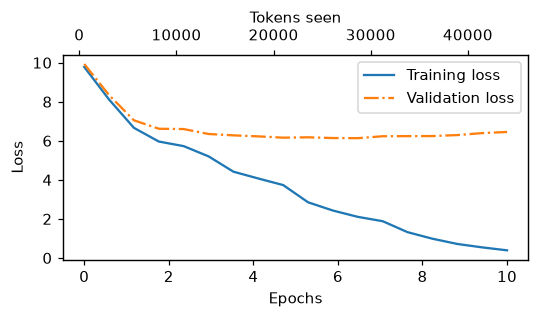

In [32]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    # Plot training and validation loss against epochs
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))  # only show integer labels on x-axis

    # Create a second x-axis for tokens seen
    ax2 = ax1.twiny()  # Create a second x-axis that shares the same y-axis
    ax2.plot(tokens_seen, train_losses, alpha=0)  # Invisible plot for aligning ticks
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()  # Adjust layout to make room
    plt.savefig("loss-plot.pdf")
    plt.show()

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

Grafik ini adalah versi Figure 5.12 buku, digambar dari catatan loss training di atas. Sumbu bawah menunjukkan epoch, sumbu atas jumlah token input yang sudah diproses: 44,032 token di evaluasi terakhir, yaitu 86 update x 512 token.

Buku membaca kurva ini sebagai *overfitting* yang dimulai sesudah epoch 2: model makin pandai menebak teks training, tapi kemampuan itu tidak ikut berlaku di teks yang belum pernah ia lihat. Kalau dilihat dari angkanya, ceritanya tidak sesederhana itu. Loss validation masih turun sampai step 55 di epoch 7, dari 6.616 di akhir epoch 2 menjadi 6.134. Yang terjadi sesudah epoch 2 adalah celah yang terus melebar: dalam rentang yang sama, loss training turun hampir 3.9 poin (dari 5.961 ke 2.104), sedangkan loss validation hanya turun sekitar 0.5. Model masih mempelajari sedikit hal yang juga berlaku di teks baru, tapi jauh lebih banyak hal yang hanya berlaku di teks training.

Kalau training dihentikan begitu loss validation mencapai titik terendahnya, yang disebut *early stopping*, training akan berhenti di step 55. Hanya saja loss validation di sini dihitung dari satu batch berisi 512 token, jadi posisi titik terendah itu sendiri cukup berisik. Sel dari repo ini juga menyimpan grafiknya sebagai `loss-plot.pdf`.

In [33]:
# Sel tambahan: model final (90 update) diukur langsung di seluruh split, mode eval
import math

model.eval()
torch.manual_seed(123)
with torch.no_grad():
    final_train = calc_loss_loader(train_loader, model, device)
    final_val = calc_loss_loader(val_loader, model, device)
print(f"model final, seluruh split : train {final_train:.4f} ({len(train_loader)} batch) | val {final_val:.4f} ({len(val_loader)} batch)")
print(f"log terakhir (step 85)     : train {train_losses[-1]:.4f} (5 batch)  | val {val_losses[-1]:.4f}")
print(f"rata-rata geometrik p(target): train {math.exp(-final_train):.3f} | val {math.exp(-final_val):.5f}")
print(f"perplexity                 : train {math.exp(final_train):.2f} | val {math.exp(final_val):.0f}")

model final, seluruh split : train 0.2976 (9 batch) | val 6.5264 (1 batch)
log terakhir (step 85)     : train 0.3909 (5 batch)  | val 6.4521
rata-rata geometrik p(target): train 0.743 | val 0.00146
perplexity                 : train 1.35 | val 683


Model akhir, sesudah semua 90 update, mendapat loss 0.2976 di kesembilan batch training dan 6.5264 di batch validation. Angka validation bisa dibandingkan langsung dengan log, karena batch-nya sama: empat update terakhir menaikkannya dari 6.4521 ke 6.5264. Angka training tidak bisa dibandingkan semudah itu, karena 0.3909 di log adalah rata-rata 5 batch yang diacak, sedangkan 0.2976 di sini rata-rata seluruh 9 batch.

Loss lebih mudah dibayangkan kalau diubah kembali menjadi probabilitas. `exp(-loss)` adalah rata-rata geometrik probabilitas yang diberikan model kepada token target. Di teks training angkanya 0.743, jadi token yang benar biasanya mendapat sebagian besar probabilitas. Di teks validation hanya 0.00146, kira-kira 1/683. Dalam perplexity: 1.35 untuk training dan 683 untuk validation. Bandingkan dengan model acak tadi, yang perplexity-nya sekitar 59 ribu. Model ini jauh lebih baik di keduanya, tapi di teks training ia hampir tidak pernah ragu, sedangkan di teks baru ia masih ragu di antara ratusan pilihan. Perlu dicatat, rata-rata geometrik ini bukan akurasi; ia tidak mengatakan berapa persen token yang ditebak dengan benar.

Kalimat-kalimat lancar di epoch 9 dan 10 tadi terasa mencurigakan. Buku menyarankan cara sederhana untuk memeriksa hafalan: cari potongan teks hasil generate di file aslinya. Sel kecil berikut melakukannya untuk dua frasa, satu dari contoh epoch 9 dan satu dari epoch 10.

In [34]:
# Sel tambahan: apakah frasa hasil generate ada verbatim di The Verdict, dan di split mana?
for phrase in ["quite insensible to the irony", "was one of the axioms he laid down across the Sevres"]:
    pos = text_data.find(phrase)
    where = "train" if 0 <= pos < split_idx else ("validation" if pos >= split_idx else "-")
    print(f"{phrase!r}: muncul {text_data.count(phrase)}x, posisi karakter {pos} (split {where}, batas split {split_idx})")

'quite insensible to the irony': muncul 1x, posisi karakter 13246 (split train, batas split 18431)
'was one of the axioms he laid down across the Sevres': muncul 1x, posisi karakter 4235 (split train, batas split 18431)


Kedua frasa ada di cerpen aslinya, masing-masing satu kali, dan keduanya di bagian training: di posisi karakter 13,246 dan 4,235, sedangkan batas pembagiannya ada di 18,431. Jadi kalimat-kalimat lancar itu bukan kalimat baru, melainkan salinan dari teks training.

Kalau dihitung, ini tidak mengherankan. Data training hanya 4,608 token, dan selama 10 epoch setiap token dilihat 10 kali. Model dengan 162 juta parameter lebih dari cukup untuk menyimpan seluruh teks itu, dan greedy decoding selalu mengambil jalur yang paling mungkin, yang tidak lain adalah jalur yang sudah dihafal. Buku mencatat bahwa pretraining sungguhan biasanya hanya berjalan sekitar satu epoch atas dataset yang jauh lebih besar, sehingga hafalan seperti ini tidak muncul dengan cara yang sama.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.13.png" width="700">

**Figure 5.13** Empat dari tujuh tujuan bab sudah tercapai. Model sudah bisa menghasilkan teks yang koheren, tapi sering menyalin teks training apa adanya; berikutnya, strategi decoding untuk teks yang lebih beragam.

## 5.3 Decoding strategies to control randomness

`generate_text_simple` selalu mengambil argmax, jadi untuk prompt yang sama ia selalu menghasilkan teks yang sama, dan untuk model yang menghafal, teks itu adalah salinan data training. *Decoding* adalah cara memilih token berikutnya dari distribusi yang dihasilkan model. Bagian ini mengganti argmax dengan *sampling*, yaitu memilih token secara acak sesuai probabilitasnya, dengan dua pengatur: *temperature* dan *top-k*.

Sel berikut memindahkan model ke CPU dan ke mode eval (dropout dimatikan), lalu menghasilkan 25 token secara greedy sebagai titik awal. Di notebook ini model memang sudah berada di CPU sejak training.

In [35]:
# NEW: use CPU here as inference is cheap with 
# this model and to ensure readers get same results in the
# remaining sections of this book
inference_device = torch.device("cpu")

model.to(inference_device)
model.eval()

tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(inference_device),
    max_new_tokens=25,
    context_size=GPT_CONFIG_124M["context_length"]
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed lun


Model melanjutkan *Every effort moves you* dengan *know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed lun*, kalimat hafalan yang sama dengan contoh epoch 10, dan sama persis dengan buku. Kecocokan ini lebih ketat daripada log tiga desimal tadi: 25 argmax berturut-turut harus jatuh ke token yang sama, padahal satu logit yang bergeser cukup jauh bisa membalik satu argmax dan membelokkan seluruh sisa kalimat.

Koreksi kecil untuk teks buku: di 5.3.3 dan Exercise 5.3 buku menyebut fungsi `generate_simple`, padahal namanya `generate_text_simple`.

### 5.3.1 Temperature scaling

Supaya efek temperature bisa diikuti dengan mata, kita pakai contoh mainan: kosakata sembilan kata dan satu vektor logit untuk token sesudah *every effort moves you*. Greedy decoding cukup memilih logit terbesar.

In [36]:
vocab = { 
    "closer": 0,
    "every": 1, 
    "effort": 2, 
    "forward": 3,
    "inches": 4,
    "moves": 5, 
    "pizza": 6,
    "toward": 7,
    "you": 8,
} 

inverse_vocab = {v: k for k, v in vocab.items()}

# Suppose input is "every effort moves you", and the LLM
# returns the following logits for the next token:
next_token_logits = torch.tensor(
    [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

probas = torch.softmax(next_token_logits, dim=0)
next_token_id = torch.argmax(probas).item()

# The next generated token is then as follows:
print(inverse_vocab[next_token_id])

forward


Logit terbesar, 6.75, ada di indeks 3, jadi greedy memilih `forward`. Untuk sampling, argmax diganti dengan `torch.multinomial`, yang mengambil satu indeks secara acak dengan peluang sebanding dengan probabilitasnya.

In [37]:
torch.manual_seed(123)
next_token_id = torch.multinomial(probas, num_samples=1).item()
print(inverse_vocab[next_token_id])

forward


Satu sampel dengan seed 123 juga jatuh di `forward`, token yang paling mungkin. Satu sampel belum memperlihatkan apa-apa; distribusinya baru terlihat kalau sampling diulang berkali-kali.

In [38]:
def print_sampled_tokens(probas):
    torch.manual_seed(123) # Manual seed for reproducibility
    sample = [torch.multinomial(probas, num_samples=1).item() for i in range(1_000)]
    sampled_ids = torch.bincount(torch.tensor(sample), minlength=len(probas))
    for i, freq in enumerate(sampled_ids):
        print(f"{freq} x {inverse_vocab[i]}")

print_sampled_tokens(probas)

73 x closer
0 x every
0 x effort
582 x forward
2 x inches
0 x moves
0 x pizza
343 x toward
0 x you


Dari 1,000 sampel, `forward` muncul 582 kali, `toward` 343 kali, `closer` 73 kali, `inches` 2 kali, dan lima kata lain tidak pernah. Frekuensi ini mengikuti probabilitas softmax-nya: dihitung dari logit di atas, `forward` mendapat 0.5721, `toward` 0.3576, dan `closer` 0.0609. Untuk ketiga kata itu, selisih frekuensi dari harapannya tidak lebih dari sekitar 1.6 simpangan baku, wajar untuk 1,000 sampel. Satu kata lain layak diperhatikan: `you` mendapat probabilitas 0.0040, jadi diharapkan muncul sekitar 4 kali, tapi tidak muncul sama sekali. Itu jarang, peluangnya sekitar 2%, tapi masih mungkin terjadi.

Delapan baris yang dicetak buku sama dengan hasil ini; yang tidak ada di buku justru baris `0 x you`. Kenapa buku hanya mencetak delapan baris? Jawabannya ada di satu argumen yang hilang (Errata #1 di notebook ini). Sel dari repo di atas memakai `torch.bincount(..., minlength=len(probas))`, sehingga selalu ada sembilan hitungan. Versi buku, dan juga solusi Exercise 5.1 di repo, memanggil `bincount` tanpa `minlength`, sehingga panjang tensor hitungannya berhenti di ID terbesar yang kebetulan tersampel. Indeks 8 (`you`) tidak pernah tersampel, jadi baris `0 x you` hilang begitu saja. Kodenya tidak error; ia hanya diam-diam menyembunyikan token bernilai nol di ujung kosakata. Exercise 5.1 di bawah menjalankan versi buku dan memperlihatkan efeknya.

*Temperature* membagi logit dengan sebuah angka $T > 0$ sebelum softmax: $p_i \propto e^{z_i / T}$. Kalau $T < 1$, jarak antar-logit membesar, sehingga distribusinya lebih tajam dan token teratas makin dominan. Kalau $T > 1$, jaraknya mengecil, sehingga distribusinya lebih rata dan token-token yang kurang mungkin ikut mendapat kesempatan. Kalau $T$ mendekati 0, sampling makin mirip argmax. Kita coba tiga nilai: 1 (tanpa perubahan), 0.1, dan 5.

In [39]:
def softmax_with_temperature(logits, temperature):
    scaled_logits = logits / temperature
    return torch.softmax(scaled_logits, dim=0)

# Temperature values
temperatures = [1, 0.1, 5]  # Original, higher confidence, and lower confidence

# Calculate scaled probabilities
scaled_probas = [softmax_with_temperature(next_token_logits, T) for T in temperatures]

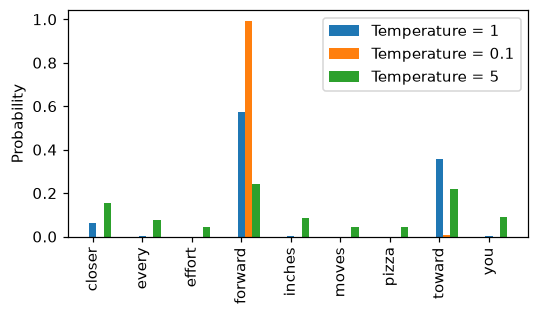

In [40]:
# Plotting
x = torch.arange(len(vocab))
bar_width = 0.15

fig, ax = plt.subplots(figsize=(5, 3))
for i, T in enumerate(temperatures):
    rects = ax.bar(x + i * bar_width, scaled_probas[i], bar_width, label=f'Temperature = {T}')

ax.set_ylabel('Probability')
ax.set_xticks(x)
ax.set_xticklabels(vocab.keys(), rotation=90)
ax.legend()

plt.tight_layout()
plt.savefig("temperature-plot.pdf")
plt.show()

Grafik ini adalah versi Figure 5.14 buku: tiga batang per kata, untuk T = 1, 0.1, dan 5. Pada T = 0.1, `forward` mendapat probabilitas 0.9910 dan kata-kata lain hampir nol. Pada T = 5 distribusinya jauh lebih rata: kata yang paling mungkin turun ke 0.2421, dan `pizza` -- kata yang tidak masuk akal sesudah *every effort moves you* -- naik ke 0.0430. Sel dari repo ini juga menyimpan grafiknya sebagai `temperature-plot.pdf`.

Dua sel berikutnya mengambil 1,000 sampel di kedua temperature ekstrem.

In [41]:
print_sampled_tokens(scaled_probas[1])

0 x closer
0 x every
0 x effort
985 x forward
0 x inches
0 x moves
0 x pizza
15 x toward
0 x you


Pada T = 0.1, `forward` muncul 985 kali dan `toward` 15 kali. Hampir greedy, tapi belum sepenuhnya. Selisih logit `forward` dan `toward`, 6.75 - 6.28 = 0.47, membesar menjadi 4.7 setelah dibagi 0.1, dan dengan selisih sebesar itu `toward` masih mendapat probabilitas sekitar 0.009. Logit-logit lain terlalu jauh di bawah untuk pernah terpilih.

In [42]:
print_sampled_tokens(scaled_probas[2])

165 x closer
75 x every
42 x effort
239 x forward
71 x inches
46 x moves
32 x pizza
227 x toward
103 x you


Pada T = 5 kesembilan kata muncul, termasuk `pizza` 32 kali dan `every` 75 kali, padahal `every` sudah ada di prompt. Probabilitas tertinggi hanya 0.2421, jadi teks yang dihasilkan dengan temperature setinggi ini sebagian besar acak. Temperature tinggi memang menambah keragaman, tapi harganya adalah token-token yang tidak masuk akal.

#### Exercise 5.1

*Cetak frekuensi sampling untuk ketiga temperature di Figure 5.14. Berapa kali `pizza` tersampel di masing-masing? Adakah cara yang lebih cepat dan lebih akurat untuk mengetahuinya?*

Tiga sel berikut adalah solusi resmi dari repo, dijalankan apa adanya. Perhatikan bahwa `print_sampled_tokens` di sini adalah versi buku, tanpa `minlength`.

In [43]:
import torch

vocab = { 
    "closer": 0,
    "every": 1, 
    "effort": 2, 
    "forward": 3,
    "inches": 4,
    "moves": 5, 
    "pizza": 6,
    "toward": 7,
    "you": 8,
} 
inverse_vocab = {v: k for k, v in vocab.items()}

next_token_logits = torch.tensor(
    [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

def print_sampled_tokens(probas):
    torch.manual_seed(123)
    sample = [torch.multinomial(probas, num_samples=1).item() for i in range(1_000)]
    sampled_ids = torch.bincount(torch.tensor(sample))
    for i, freq in enumerate(sampled_ids):
        print(f"{freq} x {inverse_vocab[i]}")


def softmax_with_temperature(logits, temperature):
    scaled_logits = logits / temperature
    return torch.softmax(scaled_logits, dim=0)


temperatures = [1, 0.1, 5]  # Original, higher, and lower temperature
scaled_probas = [softmax_with_temperature(next_token_logits, T) for T in temperatures]

In [44]:
for i, probas in enumerate(scaled_probas):
    print("\n\nTemperature:", temperatures[i])
    print_sampled_tokens(probas)



Temperature: 1
73 x closer
0 x every
0 x effort
582 x forward
2 x inches
0 x moves
0 x pizza
343 x toward


Temperature: 0.1
0 x closer
0 x every
0 x effort
985 x forward
0 x inches
0 x moves
0 x pizza
15 x toward


Temperature: 5
165 x closer
75 x every
42 x effort
239 x forward
71 x inches
46 x moves
32 x pizza
227 x toward
103 x you


`pizza` tersampel 0 kali di T = 1, 0 kali di T = 0.1, dan 32 kali di T = 5. Lihat juga jumlah baris per temperature: delapan, delapan, lalu sembilan. Itulah Errata #1 yang terlihat langsung. Di T = 1 dan T = 0.1, ID 8 (`you`) tidak pernah tersampel, jadi barisnya hilang; di T = 5 semua ID tersampel, jadi kesembilan baris muncul. Pembaca yang menjumlahkan semua baris untuk memeriksa total 1,000 tetap mendapat 1,000, sehingga bug ini lolos dari pemeriksaan sederhana.

In [45]:
temp5_idx = 2
pizza_idx = 6

scaled_probas[temp5_idx][pizza_idx]

tensor(0.0430)

Untuk bagian kedua pertanyaan, sebenarnya tidak perlu sampling sama sekali. Frekuensi yang diharapkan adalah probabilitas softmax itu sendiri: `0.0430` untuk `pizza` di T = 5, atau sekitar 43 per 1,000 sampel. Sampling 1,000 kali memberi 32, meleset 11. Apakah itu banyak? Sel berikut membandingkan selisih itu dengan derau sampling yang wajar, untuk ketiga temperature sekaligus.

In [46]:
# Sel tambahan: probabilitas eksak vs Monte Carlo 1,000 sampel, untuk "pizza" di tiga temperature
import math

for T, sp in zip(temperatures, scaled_probas):
    p = sp[vocab["pizza"]].item()
    torch.manual_seed(123)
    mc = sum(torch.multinomial(sp, num_samples=1).item() == vocab["pizza"] for _ in range(1_000))
    sd = math.sqrt(1_000 * p * (1 - p))
    z = (mc - 1_000 * p) / sd if sd > 0 else float("nan")
    print(f"T={T:<4} p(pizza) = {p:.3e}  harapan per 1000 = {1_000 * p:8.3f}  Monte Carlo = {mc:3d}  "
          f"sd = {sd:6.3f}  z = {z:+.2f}")

T=1    p(pizza) = 1.012e-04  harapan per 1000 =    0.101  Monte Carlo =   0  sd =  0.318  z = -0.32
T=0.1  p(pizza) = 2.972e-38  harapan per 1000 =    0.000  Monte Carlo =   0  sd =  0.000  z = -0.00
T=5    p(pizza) = 4.300e-02  harapan per 1000 =   42.998  Monte Carlo =  32  sd =  6.415  z = -1.71


Di T = 5, harapannya 43.0 dan hasil sampling 32, selisih -1.71 simpangan baku: masih dalam batas derau yang wajar untuk 1,000 sampel. Di T = 1 dan T = 0.1, probabilitas `pizza` begitu kecil (sekitar `1.0e-04` dan `3.0e-38`) sehingga 1,000 sampel praktis tidak akan pernah melihatnya. Di T = 1, rata-rata dibutuhkan sekitar 9,900 sampel untuk melihat satu `pizza`; di T = 0.1, jumlah sampel yang dibutuhkan jauh melampaui apa pun yang bisa dijalankan.

Jadi probabilitas eksak lebih cepat, karena cukup satu softmax, dan lebih akurat, karena tidak ada derau. Untuk kejadian langka, ia satu-satunya cara yang realistis.

### 5.3.2 Top-k sampling

Temperature tinggi menambah keragaman, tapi juga memberi kesempatan pada token yang tidak masuk akal, seperti `pizza` tadi. *Top-k sampling* memotong ekor itu: hanya k logit terbesar yang dipertahankan, dan sisanya diganti $-\infty$, sehingga probabilitasnya tepat nol setelah softmax. Ini trik masking yang sama dengan causal attention di Chapter 3.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.15.png" width="700">

**Figure 5.15** Top-k sampling dengan k = 3: tiga logit terbesar dipertahankan, sisanya diganti -inf, sehingga softmax memberi probabilitas nol untuk semua token di luar tiga besar.

In [47]:
top_k = 3
top_logits, top_pos = torch.topk(next_token_logits, top_k)

print("Top logits:", top_logits)
print("Top positions:", top_pos)

Top logits: tensor([6.7500, 6.2800, 4.5100])
Top positions: tensor([3, 7, 0])


Tiga logit terbesar, 6.75, 6.28, dan 4.51, ada di posisi 3, 7, dan 0, yaitu `forward`, `toward`, dan `closer`. Ambang batasnya adalah yang terkecil di antara ketiganya, `top_logits[-1]` = 4.51: setiap logit di bawahnya akan dibuang.

In [48]:
new_logits = torch.where(
    condition=next_token_logits < top_logits[-1],
    input=torch.tensor(float("-inf")), 
    other=next_token_logits
)

print(new_logits)

tensor([4.5100,   -inf,   -inf, 6.7500,   -inf,   -inf,   -inf, 6.2800,   -inf])


Enam posisi di bawah ambang menjadi `-inf`, dan tiga sisanya tidak berubah.

In [49]:
topk_probas = torch.softmax(new_logits, dim=0)
print(topk_probas)

tensor([0.0615, 0.0000, 0.0000, 0.5775, 0.0000, 0.0000, 0.0000, 0.3610, 0.0000])


Probabilitasnya kini 0.0615 untuk `closer`, 0.5775 untuk `forward`, dan 0.3610 untuk `toward`, sisanya tepat nol. Massa probabilitas yang semula dipegang enam token lain, sekitar 0.0094 secara total, dibagikan ulang ke tiga token yang tersisa sebanding dengan probabilitas masing-masing. Karena itu `forward` hanya naik sedikit, dari 0.5721 ke 0.5775. Dipadukan dengan temperature tinggi, top-k memberi keragaman di antara token-token yang masuk akal saja.

### 5.3.3 Modifying the text generation function

Listing 5.4 menggabungkan keduanya dalam satu fungsi `generate`. Top-k diterapkan lebih dulu pada logit. Lalu, kalau `temperature > 0`, logit dibagi temperature dan token disampling dengan `multinomial`; kalau `temperature == 0`, fungsi kembali ke argmax. Ada juga argumen `eos_id` untuk berhenti lebih awal saat model memilih token akhir teks.

Versi di repo menambahkan satu baris yang ditandai "not in book": mengurangkan nilai maksimum setiap baris sebelum softmax, supaya hasilnya setara di MPS. Di CPU baris ini tidak mengubah apa pun, karena softmax PyTorch sudah melakukan pengurangan yang sama di dalamnya.

In [50]:
def generate(model, idx, max_new_tokens, context_size, temperature=0.0, top_k=None, eos_id=None):

    # For-loop is the same as before: Get logits, and only focus on last time step
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]

        # New: Filter logits with top_k sampling
        if top_k is not None:
            # Keep only top_k values
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1]
            logits = torch.where(logits < min_val, torch.tensor(float("-inf")).to(logits.device), logits)

        # New: Apply temperature scaling
        if temperature > 0.0:
            logits = logits / temperature

            # New (not in book): numerical stability tip to get equivalent results on mps device
            # subtract rowwise max before softmax
            logits = logits - logits.max(dim=-1, keepdim=True).values
            
            # Apply softmax to get probabilities
            probs = torch.softmax(logits, dim=-1)  # (batch_size, context_len)

            # Sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1)  # (batch_size, 1)

        # Otherwise same as before: get idx of the vocab entry with the highest logits value
        else:
            idx_next = torch.argmax(logits, dim=-1, keepdim=True)  # (batch_size, 1)

        if idx_next == eos_id:  # Stop generating early if end-of-sequence token is encountered and eos_id is specified
            break

        # Same as before: append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1)  # (batch_size, num_tokens+1)

    return idx

In [51]:
torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(inference_device),
    max_new_tokens=15,
    context_size=GPT_CONFIG_124M["context_length"],
    top_k=25,
    temperature=1.4
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you stand to work on surprise, a one of us had gone with random-


Hasilnya *Every effort moves you stand to work on surprise, a one of us had gone with random-*, sama dengan buku walaupun sel ini memakai `generate` versi repo dengan baris tambahan tadi: 15 langkah sampling dengan seed 123, top-25, dan T = 1.4 menghasilkan token yang persis sama.

Kalimatnya tidak lagi berbunyi seperti kalimat hafalan dari epoch 10, dan buku memakainya untuk menunjukkan bahwa strategi decoding mengurangi hafalan. Seberapa banyak? Satu kalimat belum bisa menjawabnya; Under the hood 2 sebentar lagi akan mengukurnya.

Sebelum itu, perhatikan satu batas Listing 5.4 (Errata #2 di notebook ini): `generate` hanya bekerja untuk batch berisi satu prompt. Komentar di listing menyebut bentuk `(batch_size, ...)`, tapi ada dua baris yang tidak tahan batch lebih dari satu. Yang pertama, `min_val = top_logits[:, -1]` berbentuk `(B,)`, padahal ia harus dibandingkan per baris dengan logit berbentuk `(B, 50257)`. Yang kedua, `if idx_next == eos_id` meminta satu nilai benar-salah dari tensor berbentuk `(B, 1)`. Di bab ini `generate` hanya dipanggil dengan satu prompt, jadi masalahnya tidak pernah terlihat. Sel berikut mencobanya dengan dua prompt.

In [52]:
# Sel tambahan: Errata #2 -- generate() Listing 5.4 dengan batch dua prompt
import traceback

batch = torch.cat([text_to_token_ids("Every effort moves you", tokenizer),
                   text_to_token_ids("I had always thought", tokenizer)[:, :4]], dim=0)
print("batch shape:", tuple(batch.shape))
for kwargs in [dict(temperature=0.0), dict(temperature=1.0, top_k=5), dict(temperature=0.0, eos_id=50256)]:
    try:
        out = generate(model=model, idx=batch, max_new_tokens=3, context_size=256, **kwargs)
        print(f"{kwargs}: ok, output shape {tuple(out.shape)}")
    except RuntimeError as e:
        print(f"{kwargs}: RuntimeError: {e}")
min_val_fixed = torch.topk(torch.randn(2, 50257), 5)[0][:, -1:]
print("perbaikan: top_logits[:, -1:] berbentuk", tuple(min_val_fixed.shape), "-> broadcast per baris")

batch shape: (2, 4)
{'temperature': 0.0}: ok, output shape (2, 7)
{'temperature': 1.0, 'top_k': 5}: RuntimeError: The size of tensor a (50257) must match the size of tensor b (2) at non-singleton dimension 1
{'temperature': 0.0, 'eos_id': 50256}: RuntimeError: Boolean value of Tensor with more than one value is ambiguous
perbaikan: top_logits[:, -1:] berbentuk (2, 1) -> broadcast per baris


Tanpa top-k dan tanpa `eos_id`, batch dua prompt berjalan normal dan menghasilkan bentuk `(2, 7)`. Dengan `top_k=5`, `torch.where` gagal karena logit berbentuk `(2, 50257)` dibandingkan dengan ambang berbentuk `(2,)`, dan PyTorch mencoba mencocokkan dimensi 50,257 dengan 2. Dengan `eos_id`, perbandingan `idx_next == eos_id` menghasilkan tensor dua elemen yang tidak bisa dipakai di `if`.

Perbaikan untuk masalah pertama cukup satu karakter: `min_val = top_logits[:, -1:]`, yang berbentuk `(B, 1)` sehingga dibandingkan per baris, seperti terlihat di baris terakhir output. Untuk `eos_id` perlu keputusan desain: berhenti ketika semua baris sudah selesai, misalnya dengan `(idx_next == eos_id).all()`, atau mencatat baris mana yang sudah selesai dan terus mengisi sisanya. Repo sendiri sudah mengakui batas yang kedua: `gpt_generate.py` yang diunduh di setup menolak `eos_id` untuk batch lebih dari satu dengan pesan "EOS stopping currently supports batch size 1 only". Masalah top-k-nya masih ada di file yang sama.

#### Under the hood 2 -- meteran hafalan

Buku menyatakan bahwa temperature dan top-k mengurangi hafalan. Klaim itu bisa diukur. Teks training ditokenisasi, lalu semua potongan 8 token berturut-turut (*8-gram*) di dalamnya dikumpulkan dalam satu himpunan. Untuk setiap strategi decoding, model menghasilkan 50 token dari *Every effort moves you* dengan 8 seed berbeda; greedy cukup satu kali, karena hasilnya selalu sama. Lalu dihitung berapa persen 8-gram di teks hasil generate yang juga ada di teks training, berapa panjang potongan terpanjang yang tersalin utuh, dan berapa dari 8 sampel yang berbeda satu sama lain.

Angka itu butuh pembanding. Pembanding alaminya adalah teks validation asli, yang ditulis pengarang yang sama dalam cerita yang sama: berapa persen 8-gram-nya kebetulan juga muncul di teks training?

In [53]:
# UTH 2 (sel tambahan): meteran hafalan -- 8-gram verbatim dari split train, per strategi decoding
N, NEW = 8, 50
train_ids = tokenizer.encode(train_data)
val_ids = tokenizer.encode(val_data)
train_grams = {tuple(train_ids[i:i + N]) for i in range(len(train_ids) - N + 1)}

def verbatim(ids):
    hits = [tuple(ids[i:i + N]) in train_grams for i in range(len(ids) - N + 1)]
    run = best = 0
    for h in hits:
        run = run + 1 if h else 0
        best = max(best, run)
    return sum(hits) / len(hits), (best + N - 1 if best else 0)

prompt_ids = text_to_token_ids("Every effort moves you", tokenizer)
configs = [("greedy (argmax)", 0.0, None), ("T=0.7, top-k=5", 0.7, 5), ("T=1.0, top-k=25", 1.0, 25),
           ("T=1.4, top-k=25 (buku)", 1.4, 25), ("T=1.0, tanpa top-k", 1.0, None), ("T=2.0, tanpa top-k", 2.0, None)]
model.eval()
uth2 = {}
print(f"{'strategi':<24}{'8-gram verbatim':>17}{'run terpanjang':>16}{'sampel unik':>13}")
for name, T, k in configs:
    rates, runs, outs = [], [], set()
    for seed in ([123] if T == 0.0 else range(8)):
        torch.manual_seed(seed)
        out = generate(model=model, idx=prompt_ids, max_new_tokens=NEW, context_size=256, temperature=T, top_k=k)
        cont = out[0, max(0, prompt_ids.shape[1] - (N - 1)):].tolist()   # tiap 8-gram memuat >= 1 token baru
        r, l = verbatim(cont)
        rates.append(r); runs.append(l); outs.add(tuple(cont))
    uth2[name] = dict(rate=sum(rates) / len(rates), run=max(runs), uniq=len(outs), n=len(rates))
    print(f"{name:<24}{uth2[name]['rate']:>16.1%}{uth2[name]['run']:>12} tok{len(outs):>9}/{len(rates)}")

windows = [val_ids[i:i + NEW + N - 1] for i in range(0, len(val_ids) - NEW - N + 1, NEW)]
val_ref = sum(verbatim(w)[0] for w in windows) / len(windows)
print(f"{'teks validation asli':<24}{val_ref:>16.1%}   ({len(windows)} jendela {NEW} token)")

strategi                  8-gram verbatim  run terpanjang  sampel unik
greedy (argmax)                    89.4%          49 tok        1/1
T=0.7, top-k=5                     66.8%          51 tok        7/8
T=1.0, top-k=25                    31.9%          33 tok        8/8
T=1.4, top-k=25 (buku)             10.6%          17 tok        8/8
T=1.0, tanpa top-k                  4.0%          17 tok        8/8
T=2.0, tanpa top-k                  0.0%           0 tok        8/8
teks validation asli                0.0%   (10 jendela 50 token)


Greedy decoding menyalin hampir semuanya: 89.4% 8-gram-nya ada di teks training, dan potongan tersalin terpanjangnya 49 token, hampir seluruh 50 token yang dihasilkan. Kalimat greedy adalah penelusuran ulang jalur yang sudah dihafal.

Makin longgar pengaturannya, makin sedikit yang tersalin: 66.8% untuk T = 0.7 dengan top-5, 31.9% untuk T = 1.0 dengan top-25, dan 10.6% untuk pengaturan buku, T = 1.4 dengan top-25, dengan kedelapan sampel berbeda satu sama lain. Tapi hafalannya belum hilang, karena potongan tersalin terpanjang di pengaturan buku masih 17 token. Sampling tidak menghapus apa yang dihafal; ia hanya membuat model lebih sering melompat dari satu potongan hafalan ke potongan lain.

Satu baris di tabel itu layak diperhatikan. T = 1.0 tanpa top-k hanya menyalin 4.0%, lebih rendah daripada pengaturan buku walaupun temperature-nya lebih kecil. Melepas top-k membuka ekor puluhan ribu token, dan satu token dari ekor itu sudah cukup untuk memutus rangkaian 8-gram. Di ujung lain, T = 2.0 tanpa top-k tidak menyalin satu pun potongan 8 token di kedelapan sampelnya. Teksnya tidak dicetak di sini, tapi dengan ekor distribusi yang dibuka selebar itu, hampir pasti harganya adalah teks yang tidak koheren; pengulangan Exercise 5.2 dengan bobot GPT-2 di 5.5 nanti memperlihatkan seperti apa teks dengan temperature tinggi tanpa top-k.

Patokannya adalah teks validation asli. Dari sepuluh jendela 50 token, tidak satu pun potongan 8 token-nya (0.0%) muncul di bagian training, walaupun pengarang dan ceritanya sama. Angka ini patokan untuk cerita ini dan ukuran ini saja, bukan klaim umum tentang prosa.

**Strategi decoding menggeser tingkat salinan secara bertahap, tapi hafalannya sendiri tersimpan di bobot.** Pada pengaturan buku, model masih menyalin jauh di atas patokan itu. Loss model akhir sudah mengatakannya sejak tadi: 0.30 di training dan 6.53 di validation. Decoder hanya memilih seberapa sering jalur hafalan itu diikuti.

Kalau hafalan ingin dikurangi, perubahannya harus terjadi di data dan training, bukan di decoder. Arahnya sudah disebut buku di 5.2: data yang jauh lebih banyak, dan sekitar satu epoch saja alih-alih sepuluh putaran atas teks yang sama. Notebook ini tidak menguji keduanya. Berhenti di titik terendah loss validation pun belum tentu cukup. Di step 55 loss training sudah 2.104 sedangkan loss validation 6.134, jadi pada titik itu model sudah jauh lebih yakin pada teks training daripada pada teks baru. Seberapa banyak hafalan berkurang kalau training dihentikan di sana tidak diukur di sini.

#### Exercise 5.2

*Coba berbagai pengaturan temperature dan top-k. Aplikasi apa yang membutuhkan pengaturan rendah, dan aplikasi apa yang membutuhkan pengaturan tinggi?*

Tabel di Under the hood 2 adalah versi terukur dari latihan ini. Pengaturan rendah -- temperature kecil, k kecil, atau greedy -- cocok ketika satu jawaban yang tepat lebih penting daripada variasi, dan hasilnya perlu bisa diulang: ekstraksi informasi, kode, terjemahan, atau jawaban faktual yang akan diperiksa. Harganya, model selalu mengikuti jalur yang paling mungkin, termasuk kebiasaan buruknya: pengulangan, dan pada model yang overfit seperti milik kita, salinan data training.

Pengaturan tinggi cocok ketika keragaman memang tujuannya: brainstorming, fiksi, variasi teks iklan, atau menghasilkan banyak calon jawaban untuk dipilih manusia atau model lain. Harganya, koherensi turun dan token yang tidak masuk akal, seperti `pizza`, mulai muncul. Top-k menjadi pagar untuk temperature tinggi: ia membiarkan keragaman di antara pilihan yang masuk akal sambil memotong ekor yang tidak masuk akal.

Buku menyarankan latihan ini diulang setelah bobot OpenAI dimuat. Sel "Exercise 5.2, ulang" di akhir 5.5 melakukannya.

## 5.4 Loading and saving model weights in PyTorch

Training sekecil ini pun memakan beberapa menit, dan untuk LLM sungguhan biayanya bisa mencapai ratusan ribu dolar, seperti hitungan Llama 2 tadi. Hasil training perlu disimpan supaya tidak harus diulang. Cara yang dianjurkan PyTorch adalah menyimpan `state_dict`, yaitu dictionary yang memetakan nama setiap parameter ke tensornya, dengan `torch.save`. Ekstensi `.pth` hanya konvensi.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.16.png" width="700">

**Figure 5.16** Langkah 6 dari tujuh: sesudah training dan pemeriksaan, bobot disimpan supaya bisa dipakai lagi atau dilatih lebih lanjut.

In [54]:
torch.save(model.state_dict(), "model.pth")

#### Exercise 5.3

*Kombinasi pengaturan apa saja di `generate` yang membuatnya deterministik, seperti `generate_text_simple`?*

Solusi resmi memuat `model.pth` yang baru disimpan ke sebuah model baru, seolah-olah di sesi Python yang baru, lalu membandingkan `generate_text_simple` dengan `generate(temperature=0.0, top_k=None)`. Sel keduanya mengimpor `generate` dari `gpt_generate.py`. File itu mengimpor `tensorflow` di baris-baris atasnya, walaupun `generate` sama sekali tidak memakainya; di lingkungan tanpa TensorFlow, import ini tetap berhasil berkat pembaca NumPy dari sel setup.

In [55]:
import tiktoken
import torch
from previous_chapters import GPTModel


GPT_CONFIG_124M = {
    "vocab_size": 50257,  # Vocabulary size
    "context_length": 256,       # Shortened context length (orig: 1024)
    "emb_dim": 768,       # Embedding dimension
    "n_heads": 12,        # Number of attention heads
    "n_layers": 12,       # Number of layers
    "drop_rate": 0.1,     # Dropout rate
    "qkv_bias": False     # Query-key-value bias
}


torch.manual_seed(123)

tokenizer = tiktoken.get_encoding("gpt2")
model = GPTModel(GPT_CONFIG_124M)
model.load_state_dict(torch.load("model.pth", weights_only=True))
model.eval();

In [56]:
from gpt_generate import generate, text_to_token_ids, token_ids_to_text
from previous_chapters import generate_text_simple

In [57]:
# Deterministic function that used torch.argmax

start_context = "Every effort moves you"

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=25,
    context_size=GPT_CONFIG_124M["context_length"]
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed lun


Model yang dimuat dari `model.pth`, dengan argmax, menghasilkan kalimat hafalan yang sama: *know," was one of the axioms he laid down across the Sevres...*

In [58]:
# Deterministic behavior: No top_k, no temperature scaling

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens=25,
    context_size=GPT_CONFIG_124M["context_length"],
    top_k=None,
    temperature=0.0
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed lun


`generate` dengan `temperature=0.0` dan `top_k=None` memberi kalimat yang sama. Sel solusi berikutnya mengulang panggilan yang persis sama, untuk menunjukkan bahwa hasilnya tidak berubah dari panggilan ke panggilan.

In [59]:
# Deterministic behavior: No top_k, no temperature scaling

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens=25,
    context_size=GPT_CONFIG_124M["context_length"],
    top_k=None,
    temperature=0.0
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed lun


Ketiga output identik satu sama lain, dan identik dengan output greedy di awal 5.3. Ini sekaligus menunjukkan bahwa `model.pth` menyimpan bobot dengan lengkap: model baru yang dimuat dari file menghasilkan token yang sama dengan model asalnya. Dengan `temperature=0.0`, `generate` memilih token dengan argmax. Kalau `top_k` diisi, masking top-k memang dikerjakan lebih dulu, tapi masking itu tidak pernah membuang logit terbesar, jadi nilai `top_k` berapa pun tidak mengubah hasil.

Jawabannya belum lengkap tanpa satu kombinasi lagi: `top_k=1` dengan temperature berapa pun. Sesudah masking hanya satu logit yang tersisa, softmax memberinya probabilitas tepat 1, dan `multinomial` tidak punya pilihan lain. Sel berikut menghitung berapa output berbeda yang dihasilkan 5 seed untuk empat pengaturan.

In [60]:
# Sel tambahan: setelan mana yang deterministik? jumlah output berbeda dari 5 seed
idx = text_to_token_ids("Every effort moves you", tokenizer)
for name, kw in [("temperature=0.0", dict(temperature=0.0)),
                 ("top_k=1, temperature=1.4", dict(top_k=1, temperature=1.4)),
                 ("temperature=0.1, top_k=None", dict(temperature=0.1)),
                 ("temperature=1.4, top_k=25", dict(top_k=25, temperature=1.4))]:
    outs = set()
    for seed in range(5):
        torch.manual_seed(seed)
        outs.add(tuple(generate(model=model, idx=idx, max_new_tokens=25,
                                context_size=GPT_CONFIG_124M["context_length"], **kw)[0].tolist()))
    print(f"{name:<30} output berbeda: {len(outs)}/5")

temperature=0.0                output berbeda: 1/5
top_k=1, temperature=1.4       output berbeda: 1/5
temperature=0.1, top_k=None    output berbeda: 1/5
temperature=1.4, top_k=25      output berbeda: 5/5


`temperature=0.0` dan `top_k=1` sama-sama hanya memberi satu output untuk kelima seed, sedangkan T = 1.4 dengan top-25 memberi lima output berbeda. `top_k=1` deterministik karena konstruksinya, seperti dijelaskan tadi.

Baris ketiga lebih licin. `temperature=0.1` tanpa top-k juga memberi satu output untuk kelima seed, tapi bukan karena konstruksi: probabilitas token kedua tidak pernah tepat nol, hanya sangat kecil untuk model yang seyakin ini. Pada model yang kurang yakin, atau teks yang lebih panjang, hasilnya bisa bercabang. Bahkan pengaturan yang deterministik secara konstruksi pun tetap memilih token dari logit float32, jadi hasilnya sama di hardware lain hanya selama logit di sana cukup dekat untuk tidak membalik satu argmax pun.

Kembali ke alur bab: bobot yang tersimpan dimuat ke instance `GPTModel` yang baru. Sel ini juga memakai versi dari masa buku terbit, dengan device `cuda` atau `cpu`. `map_location=device` memastikan tensor dimuat ke device yang tersedia, walaupun file-nya disimpan dari device lain, dan `model.eval()` mematikan dropout untuk inferensi.

In [61]:
model = GPTModel(GPT_CONFIG_124M)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.load_state_dict(torch.load("model.pth", map_location=device, weights_only=True))
model.eval();

Untuk melanjutkan training nanti, menyimpan bobot saja tidak cukup; state optimizer juga harus ikut. AdamW menyimpan dua tensor untuk setiap parameter -- rata-rata bergerak dari gradien (`exp_avg`) dan dari kuadrat gradien (`exp_avg_sq`) -- ditambah penghitung step. Tanpa keduanya, optimizer mulai lagi dari nol, dan langkah-langkah pertamanya berperilaku sangat berbeda, seperti yang akan kita ukur di Exercise 5.4.

In [62]:
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    }, 
    "model_and_optimizer.pth"
)

In [63]:
# Sel tambahan: berapa mahal menyimpan state optimizer?
import os

for f in ["model.pth", "model_and_optimizer.pth"]:
    print(f"{f:<24} {os.path.getsize(f) / 1e6:8.1f} MB")
n_params = sum(p.numel() for p in model.parameters())
print(f"parameter model          {n_params:,} x 4 byte = {n_params * 4 / 1e6:.1f} MB")
st = optimizer.state_dict()["state"][0]
print("state AdamW per parameter:", sorted(st.keys()), "| step =", int(st["step"]))

model.pth                   652.9 MB
model_and_optimizer.pth    1952.4 MB
parameter model          162,419,712 x 4 byte = 649.7 MB
state AdamW per parameter: ['exp_avg', 'exp_avg_sq', 'step'] | step = 90


`model.pth` berukuran 652.9 MB, dan isinya bisa dihitung. Ada 162,419,712 parameter float32, masing-masing 4 byte, jadi 649.7 MB. Ditambah 12 buffer causal mask, satu per blok transformer, masing-masing matriks `256 x 256` float32, sekitar 3.1 MB secara total; buffer ini ikut tersimpan karena didaftarkan dengan `register_buffer`. Sisanya sedikit overhead format file.

`model_and_optimizer.pth` berukuran 1952.4 MB, sekitar tiga kali lipat: tensor model di atas, ditambah `exp_avg` dan `exp_avg_sq` yang masing-masing sebesar seluruh parameter. State optimizer juga mencatat `step = 90`, yaitu 10 epoch x 9 batch: setiap parameter sudah menerima 90 update. Selama bobot dan kedua tensor AdamW disimpan dalam float32 seperti di sini, rasio sekitar tiga kali ini berlaku berapa pun ukuran modelnya.

In [64]:
checkpoint = torch.load("model_and_optimizer.pth", weights_only=True)

model = GPTModel(GPT_CONFIG_124M)
model.load_state_dict(checkpoint["model_state_dict"])

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0005, weight_decay=0.1)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
model.train();

In [65]:
# Sel tambahan: apa yang sebenarnya dipulihkan load_state_dict?
print("lr di konstruktor sel di atas: 0.0005 | lr setelah load_state_dict:", optimizer.param_groups[0]["lr"])
print("step AdamW yang dipulihkan  :", int(optimizer.state_dict()["state"][0]["step"]))
print("mode model                  :", "train" if model.training else "eval")

lr di konstruktor sel di atas: 0.0005 | lr setelah load_state_dict: 0.0004
step AdamW yang dipulihkan  : 90
mode model                  : train


Ada detail yang mudah terlewat. Sel dari repo membuat AdamW dengan `lr=0.0005`, tapi `load_state_dict` menimpa pengaturan itu dengan isi checkpoint, sehingga learning rate kembali ke 0.0004, nilai yang dipakai saat training. Hyperparameter di konstruktor optimizer hanya berlaku kalau checkpoint tidak membawanya. Kalau ingin memakai learning rate lain sesudah melanjutkan training, ubah `optimizer.param_groups[i]["lr"]` sesudah `load_state_dict`. Terakhir, `model.train()` di akhir sel menyalakan dropout lagi untuk training lanjutan.

#### Exercise 5.4

*Muat model dan optimizer yang sudah disimpan di sesi Python yang baru, lalu lanjutkan pretraining satu epoch lagi dengan `train_model_simple`.*

Tiga sel solusi resmi berikut memuat `model_and_optimizer.pth` yang baru disimpan, membangun ulang data loader, lalu mengimpor `train_model_simple` dari `gpt_train.py` dan melatih satu epoch, yaitu 9 update.

In [66]:
import tiktoken
import torch
from previous_chapters import GPTModel


GPT_CONFIG_124M = {
    "vocab_size": 50257,   # Vocabulary size
    "context_length": 256, # Shortened context length (orig: 1024)
    "emb_dim": 768,        # Embedding dimension
    "n_heads": 12,         # Number of attention heads
    "n_layers": 12,        # Number of layers
    "drop_rate": 0.1,      # Dropout rate
    "qkv_bias": False      # Query-key-value bias
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = tiktoken.get_encoding("gpt2")

checkpoint = torch.load("model_and_optimizer.pth", weights_only=True)
model = GPTModel(GPT_CONFIG_124M)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
model.train();

In [67]:
import os
import requests
from previous_chapters import create_dataloader_v1


file_path = "the-verdict.txt"
url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt"

if not os.path.exists(file_path):
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    text_data = response.text
    with open(file_path, "w", encoding="utf-8") as file:
        file.write(text_data)
else:
    with open(file_path, "r", encoding="utf-8") as file:
        text_data = file.read()

# The book originally used the following code below
# However, urllib uses older protocol settings that
# can cause problems for some readers using a VPN.
# The `requests` version above is more robust
# in that regard.

"""
import urllib.request

if not os.path.exists(file_path):
    with urllib.request.urlopen(url) as response:
        text_data = response.read().decode('utf-8')
    with open(file_path, "w", encoding="utf-8") as file:
        file.write(text_data)
else:
    with open(file_path, "r", encoding="utf-8") as file:
        text_data = file.read()
"""


# Train/validation ratio
train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]


torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

In [68]:
from gpt_train import train_model_simple

num_epochs = 1
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context="Every effort moves you", tokenizer=tokenizer
)

Ep 1 (Step 000000): Train loss 0.271, Val loss 6.545
Ep 1 (Step 000005): Train loss 0.244, Val loss 6.614
Every effort moves you?"  "Yes--quite insensible to the irony. She wanted him vindicated--and by me!"  He laughed again, and threw back his head to look up at the sketch of the donkey. "There were days when I


Satu epoch tambahan dengan optimizer yang dipulihkan: di step 0 loss training 0.271 dan validation 6.545, di step 5 masing-masing 0.244 dan 6.614. Dibanding model akhir di 5.2, yang loss validation-nya 6.5264, loss validation naik ke 6.614 sementara loss training tetap rendah: epoch ke-11 hanya memperdalam overfitting. Contoh teksnya kembali ke kalimat hafalan, *"Yes--quite insensible to the irony. She wanted him vindicated--and by me!"*, yang memuat frasa yang tadi kita temukan di teks training.

Buku memperingatkan bahwa tanpa state optimizer, model bisa belajar dengan kurang optimal atau bahkan gagal konvergen. Peringatan itu bisa diukur. Sel berikut memuat bobot yang sama, tapi membuat AdamW baru tanpa state, dengan seed, data, dan urutan batch yang sama.

In [69]:
# Sel tambahan: Exercise 5.4 arm B -- bobot yang sama, AdamW baru tanpa state (seed dan data identik)
import torch
from previous_chapters import GPTModel
from gpt_train import train_model_simple

checkpoint = torch.load("model_and_optimizer.pth", weights_only=True)
model_b = GPTModel(GPT_CONFIG_124M)
model_b.load_state_dict(checkpoint["model_state_dict"])
model_b.to(device)
optimizer_b = torch.optim.AdamW(model_b.parameters(), lr=0.0004, weight_decay=0.1)   # tanpa load_state_dict
model_b.train()

torch.manual_seed(123)   # sama dengan sel data loader solusi: RNG belum dipakai sebelum iterasi pertama
train_losses_b, val_losses_b, _ = train_model_simple(
    model_b, train_loader, val_loader, optimizer_b, device,
    num_epochs=1, eval_freq=5, eval_iter=5,
    start_context="Every effort moves you", tokenizer=tokenizer
)

Ep 1 (Step 000000): Train loss 0.751, Val loss 6.742
Ep 1 (Step 000005): Train loss 0.562, Val loss 6.622
Every effort moves you?" "Oh, and Mrs. . . . "I turned: "Yes--and by me!" "Mrs. Gisburn drew back his glory, he had dropped his painting, married a rich widow, and established himself in


Dengan AdamW baru, loss training sesudah update pertama melompat ke 0.751, hampir tiga kali 0.271 pada optimizer yang dipulihkan, dan loss validation 6.742 dibanding 6.545. Di step 5 loss training masih 0.562 dibanding 0.244, sedangkan loss validation sudah hampir menyusul, 6.622 dibanding 6.614.

Penyebabnya ada di langkah pertama AdamW yang baru. Ingat dua tensor state AdamW tadi: `exp_avg`, rata-rata bergerak gradien ($m$), dan `exp_avg_sq`, rata-rata bergerak kuadrat gradien ($v$). Optimizer yang baru memulai keduanya dari nol, sehingga di langkah-langkah awal nilainya terlalu kecil. AdamW mengoreksinya dengan membagi $m$ dengan $1 - \beta_1^t$ dan $v$ dengan $1 - \beta_2^t$, dengan $t$ nomor langkah dan $\beta_1$, $\beta_2$ faktor peluruhan kedua rata-rata itu; hasil koreksi ini ditulis $\hat m$ dan $\hat v$. Di langkah pertama ($t = 1$), koreksi itu membuat $\hat m = g$ dan $\hat v = g^2$, sehingga besar langkahnya, $\hat m / (\sqrt{\hat v} + \epsilon)$, menjadi $g / (|g| + \epsilon)$. Nilainya hampir $\pm 1$ untuk setiap parameter yang gradiennya jauh di atas `eps` (1e-8). Akibatnya setiap bobot seperti itu bergeser sejauh learning rate, 0.0004, berlawanan dengan tanda gradiennya, sekecil apa pun gradien itu. Bobot yang gradiennya tepat nol, misalnya baris embedding untuk token yang tidak muncul di batch, hanya terkena weight decay. Untuk model yang bobotnya sudah dilatih, ini guncangan serentak ke sebagian besar parameter. Optimizer yang dipulihkan membagi dengan $\sqrt{v}$ hasil 90 step sebelumnya, sehingga ukuran langkahnya sudah disesuaikan untuk setiap parameter.

Jadi menyimpan state optimizer bukan formalitas, terutama kalau training dilanjutkan dengan learning rate yang tidak kecil. Mekanisme langkah pertama yang sama akan muncul lagi di Under the hood 4.

## 5.5 Loading pretrained weights from OpenAI

Model kita menghafal satu cerpen dengan ongkos beberapa menit CPU. Melatih model yang benar-benar mengenal bahasa Inggris butuh data dan biaya yang jauh di luar jangkauan laptop. Untungnya OpenAI merilis bobot GPT-2, dan karena arsitektur kita sama dengan GPT-2, bobot itu bisa dipasang langsung ke `GPTModel` buatan sendiri.

Bobot itu disimpan sebagai checkpoint TensorFlow 1.x. Buku memakai TensorFlow untuk membacanya dan `tqdm` untuk progress bar unduhan. Sel repo berikut hanya berisi komentar instruksi instalasi, disusul sel yang mencetak versi kedua paket.

In [70]:
# pip install tensorflow tqdm

In [71]:
# Sel repo [130] verbatim, dibungkus try/except supaya Run all tidak berhenti bila TensorFlow tidak terpasang
import traceback

try:
    print("TensorFlow version:", version("tensorflow"))
    print("tqdm version:", version("tqdm"))
except Exception:
    traceback.print_exc()

TensorFlow version: 2.22.0rc0
tqdm version: 4.70.1


TensorFlow `2.22.0rc0`, release candidate yang sama seperti di setup, dan tqdm 4.70.1. Di lingkungan tanpa TensorFlow, sel ini mencetak `PackageNotFoundError` sebelum sempat mencetak versi `tqdm`. Pembaca NumPy dari setup sengaja tidak memalsukan data instalasi paket, jadi `importlib.metadata` tetap jujur tentang apa yang terpasang.

Perintah instalasi di buku, `pip install tensorflow>=2.15.0 tqdm>=4.66`, ditulis tanpa tanda kutip (Errata #3). Di shell, karakter `>` berarti *redirect*, yaitu mengalihkan output ke sebuah file. Sel berikut mengujinya di bash dan zsh memakai `echo` di folder sementara, jadi tidak ada yang benar-benar dipasang.

In [72]:
# Sel tambahan: Errata #3 -- requirement tanpa kutip di bash dan zsh (pakai echo, tanpa instalasi)
import shutil, subprocess, tempfile

cmd = "echo pip install tensorflow>=2.15.0 tqdm>=4.66"
for shell in ["bash", "zsh"]:
    if shutil.which(shell) is None:
        print(f"{shell}: tidak tersedia di mesin ini")
        continue
    with tempfile.TemporaryDirectory() as d:
        r = subprocess.run([shell, "-c", cmd], cwd=d, capture_output=True, text=True)
        files = {f: open(os.path.join(d, f)).read().strip() for f in sorted(os.listdir(d))}
        print(f"{shell}: exit {r.returncode}, stdout={r.stdout.strip()!r}, stderr={r.stderr.strip()!r}, file dibuat={files}")
print("perbaikan:", 'pip install "tensorflow>=2.15.0" "tqdm>=4.66"')

bash: exit 0, stdout='', stderr='', file dibuat={'=2.15.0': '', '=4.66': 'pip install tensorflow tqdm'}
zsh: exit 1, stdout='', stderr='zsh:1: 2.15.0 not found', file dibuat={}
perbaikan: pip install "tensorflow>=2.15.0" "tqdm>=4.66"


Di bash, perintahnya "berhasil" (exit 0) tanpa mencetak apa pun, dan muncul dua file baru: `=2.15.0` yang kosong, dan `=4.66` yang berisi `pip install tensorflow tqdm`. Artinya bash akan menjalankan pip tanpa batas versi dan mengalihkan outputnya ke file. Pembaca tidak melihat error apa pun, padahal batas versinya hilang. Di zsh, `>` juga berarti redirect, tapi nama file sesudahnya, `=2.15.0`, lebih dulu diproses oleh fitur zsh bernama *equals expansion*: kata yang diawali `=` diganti dengan lokasi lengkap perintah bernama sama, di sini perintah `2.15.0`. Perintah seperti itu tidak ada, jadi zsh berhenti dengan `zsh:1: 2.15.0 not found` sebelum pip sempat dipanggil. Perbaikannya cukup tanda kutip, seperti di baris terakhir output. Repo menghindari masalah ini dengan menulis `pip install tensorflow tqdm` tanpa versi sama sekali.

Berikutnya modul unduhan. Buku mengambil `gpt_download.py` langsung dari branch `main` di repo dengan `urllib`; sel buku ini tidak ada di notebook repo, yang memakai file lokal. Sel berikut menjalankan listing buku apa adanya, lalu membandingkan file dari `main` dengan salinan dari commit `cdbd33e` yang diunduh di setup.

In [73]:
# Listing buku 5.5 (tidak ada di notebook repo): unduh gpt_download.py dari branch main
import urllib.request
url = (
    "https://raw.githubusercontent.com/rasbt/"
    "LLMs-from-scratch/main/ch05/"
    "01_main-chapter-code/gpt_download.py"
)
filename = url.split('/')[-1]
urllib.request.urlretrieve(url, filename)

# Sel tambahan (lanjutan): bandingkan dengan versi commit yang dipin
digest = hashlib.sha256(open(filename, "rb").read()).hexdigest()
print("sha256 gpt_download.py dari main:", digest[:16], "| sama dengan commit dipin:", digest == SHA256["gpt_download.py"])

sha256 gpt_download.py dari main: 3e2e95f7c3bf188e | sama dengan commit dipin: True


Saat run ini, isi `gpt_download.py` di `main` masih sama dengan salinan dari commit `cdbd33e` (`True`). Tapi file itu sudah tidak sama dengan versi dari masa buku terbit, yang mengunduh dengan `urllib`: versi sekarang mengunduh dengan `requests`, memakai batas waktu dan `raise_for_status`, dan punya alamat cadangan kalau server OpenAI gagal. Karena listing buku menunjuk ke `main`, pembaca di masa depan bisa saja menerima versi yang lain lagi, dan membandingkan hash seperti di sel ini adalah cara cepat untuk mengetahuinya.

In [74]:
# Relative import from the gpt_download.py contained in this folder

from gpt_download import download_and_load_gpt2
# Alternatively:
# from llms_from_scratch.ch05 import download_and_load_gpt2

In [75]:
settings, params = download_and_load_gpt2(model_size="124M", models_dir="gpt2")

File already exists and is up-to-date: gpt2/124M/checkpoint
File already exists and is up-to-date: gpt2/124M/encoder.json
File already exists and is up-to-date: gpt2/124M/hparams.json
File already exists and is up-to-date: gpt2/124M/model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2/124M/model.ckpt.index
File already exists and is up-to-date: gpt2/124M/model.ckpt.meta
File already exists and is up-to-date: gpt2/124M/vocab.bpe


Ketujuh file checkpoint 124M dilaporkan *already exists and is up-to-date*. Fungsi unduhannya meminta ukuran file ke server, membandingkannya dengan ukuran file lokal, dan melewati unduhan kalau keduanya sama. File-file ini sudah ada dari unduhan sebelumnya; di lingkungan yang baru, sel ini menampilkan tujuh progress bar `tqdm` seperti di buku. Satu salah ketik kecil di buku: progress bar-nya tercetak `hprams.json`, padahal nama file-nya `hparams.json`.

Di dalamnya, `download_and_load_gpt2` memanggil `tf.train.list_variables` dan `tf.train.load_variable` untuk 148 variabel, lalu menyusunnya menjadi dictionary bertingkat. Di run ini semua panggilan itu dilayani TensorFlow asli; di lingkungan tanpa TensorFlow, pembaca NumPy yang mengerjakannya.

In [76]:
print("Settings:", settings)

Settings: {'n_vocab': 50257, 'n_ctx': 1024, 'n_embd': 768, 'n_head': 12, 'n_layer': 12}


`settings` adalah isi `hparams.json` dari OpenAI: kosakata 50,257, konteks 1,024, embedding 768, 12 head, dan 12 lapisan. Semuanya sama dengan `GPT_CONFIG_124M` kita, kecuali panjang konteks yang kita pangkas menjadi 256.

In [77]:
print("Parameter dictionary keys:", params.keys())

Parameter dictionary keys: dict_keys(['blocks', 'b', 'g', 'wpe', 'wte'])


`params` punya lima kunci teratas: `blocks` (daftar 12 blok transformer), `wte` (token embedding), `wpe` (positional embedding), serta `g` dan `b`, yaitu skala dan geseran LayerNorm terakhir. Nama `g` dan `b` adalah penamaan OpenAI untuk *gain* dan *bias*.

In [78]:
print(params["wte"])
print("Token embedding weight tensor dimensions:", params["wte"].shape)

[[-0.11010301 -0.03926672  0.03310751 ... -0.1363697   0.01506208
   0.04531523]
 [ 0.04034033 -0.04861503  0.04624869 ...  0.08605453  0.00253983
   0.04318958]
 [-0.12746179  0.04793796  0.18410145 ...  0.08991534 -0.12972379
  -0.08785918]
 ...
 [-0.04453601 -0.05483596  0.01225674 ...  0.10435229  0.09783269
  -0.06952604]
 [ 0.1860082   0.01665728  0.04611587 ... -0.09625227  0.07847701
  -0.02245961]
 [ 0.05135201 -0.02768905  0.0499369  ...  0.00704835  0.15519823
   0.12067825]]
Token embedding weight tensor dimensions: (50257, 768)


Matriks token embedding berukuran `(50257, 768)`: satu vektor berisi 768 angka untuk setiap token kosakata. Yang tercetak hanya pinggir matriks itu, tiga baris di awal dan tiga di akhir, dari `-0.11010301` di pojok kiri atas sampai `0.12067825` di pojok kanan bawah. Under the hood 3 nanti memeriksa seluruh isi checkpoint.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.17.png" width="700">

**Figure 5.17** Model GPT-2 tersedia dalam empat ukuran, dari 124 juta sampai 1,558 juta parameter. Arsitekturnya sama; yang berbeda hanya dimensi embedding (768 sampai 1,600), jumlah attention head (12 sampai 25), dan berapa kali blok transformer diulang (12 sampai 48).

Bobot OpenAI akan dimuat ke `GPTModel` buatan kita dengan tiga penyesuaian konfigurasi: dimensi model mengikuti ukuran yang dipilih, `context_length` kembali ke 1,024 karena tabel positional embedding OpenAI berukuran `1024 x 768`, dan `qkv_bias=True` karena GPT-2 asli memakai bias di proyeksi query, key, dan value. Buku mencatat bahwa bias QKV sudah jarang dipakai LLM modern, tapi bobot pretrained memaksa arsitektur kita mengikuti aslinya.

In [79]:
# Define model configurations in a dictionary for compactness
model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

# Copy the base configuration and update with specific model settings
model_name = "gpt2-small (124M)"  # Example model name
NEW_CONFIG = GPT_CONFIG_124M.copy()
NEW_CONFIG.update(model_configs[model_name])
NEW_CONFIG.update({"context_length": 1024, "qkv_bias": True})

gpt = GPTModel(NEW_CONFIG)
gpt.eval();

In [80]:
def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, Right: {right.shape}")
    return torch.nn.Parameter(torch.tensor(right))

`assign` mengganti sebuah parameter dengan tensor dari checkpoint, setelah memeriksa bahwa bentuk keduanya sama. Versi di atas adalah versi repo, dengan pesan error dalam satu f-string utuh. Versi cetak buku berbeda di satu tempat (Errata #4): pesannya dipecah menjadi dua string yang disambung, dan hanya string pertama yang diberi awalan `f`. Kodenya tetap berjalan, dan kesalahannya baru terlihat persis ketika pesan itu dibutuhkan, yaitu ketika bentuknya tidak cocok. Sel berikut menjalankan versi buku dengan bentuk yang sengaja salah.

In [81]:
# Sel tambahan: Errata #4 -- assign() versi cetak buku vs versi repo, dengan bentuk yang sengaja tidak cocok
def assign_book(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, "
                         "Right: {right.shape}"
                         )
    return torch.nn.Parameter(torch.tensor(right))

wrong = params["blocks"][0]["attn"]["c_attn"]["w"]      # (768, 2304), belum di-split
for fn in (assign_book, assign):
    try:
        fn(gpt.trf_blocks[0].att.W_query.weight, wrong)
    except ValueError as e:
        print(f"{fn.__name__:<12} ValueError: {e}")

assign_book  ValueError: Shape mismatch. Left: torch.Size([768, 768]), Right: {right.shape}
assign       ValueError: Shape mismatch. Left: torch.Size([768, 768]), Right: (768, 2304)


Versi buku mencetak `Right: {right.shape}` apa adanya, sedangkan versi repo mencetak `Right: (768, 2304)`. Bentuk kiri tercetak benar di keduanya. Padahal saat memetakan bobot di Listing 5.5, bentuk kananlah informasi yang paling berguna: `(768, 2304)` langsung memberi tahu bahwa tensor `c_attn` dari OpenAI belum dipecah menjadi query, key, dan value.

In [82]:
import numpy as np

def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params['wpe'])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params['wte'])
    
    for b in range(len(params["blocks"])):
        q_w, k_w, v_w = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["w"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.weight = assign(
            gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(
            gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(
            gpt.trf_blocks[b].att.W_value.weight, v_w.T)

        q_b, k_b, v_b = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["b"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.bias = assign(
            gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(
            gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(
            gpt.trf_blocks[b].att.W_value.bias, v_b)

        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight, 
            params["blocks"][b]["attn"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias, 
            params["blocks"][b]["attn"]["c_proj"]["b"])

        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight, 
            params["blocks"][b]["mlp"]["c_fc"]["w"].T)
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias, 
            params["blocks"][b]["mlp"]["c_fc"]["b"])
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight, 
            params["blocks"][b]["mlp"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias, 
            params["blocks"][b]["mlp"]["c_proj"]["b"])

        gpt.trf_blocks[b].norm1.scale = assign(
            gpt.trf_blocks[b].norm1.scale, 
            params["blocks"][b]["ln_1"]["g"])
        gpt.trf_blocks[b].norm1.shift = assign(
            gpt.trf_blocks[b].norm1.shift, 
            params["blocks"][b]["ln_1"]["b"])
        gpt.trf_blocks[b].norm2.scale = assign(
            gpt.trf_blocks[b].norm2.scale, 
            params["blocks"][b]["ln_2"]["g"])
        gpt.trf_blocks[b].norm2.shift = assign(
            gpt.trf_blocks[b].norm2.shift, 
            params["blocks"][b]["ln_2"]["b"])

    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["g"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["b"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte"])
    
    
load_weights_into_gpt(gpt, params)
gpt.to(device);

`load_weights_into_gpt` memetakan penamaan OpenAI ke modul-modul buatan kita. Ada tiga pola yang perlu diperhatikan.

Pertama, `c_attn` di checkpoint OpenAI adalah satu matriks `768 x 2304` yang menggabungkan query, key, dan value. `np.split(..., 3, axis=-1)` memecahnya menjadi tiga matriks `768 x 768`.

Kedua, semua bobot linear di-transpose dengan `.T`. OpenAI menyimpan bobot dalam susunan `[in, out]`, karena implementasi aslinya memakai lapisan `Conv1D`, sedangkan `nn.Linear` di PyTorch menyimpan `[out, in]`.

Ketiga, `out_head.weight` diisi dengan `params["wte"]`, matriks yang sama dengan token embedding. Inilah *weight tying* versi GPT-2 asli: lapisan output memakai ulang matriks embedding input. Under the hood 4 akan memeriksa apakah ikatan itu benar-benar terjadi.

Kalau satu pemetaan salah, `assign` akan menolak bentuk yang tidak cocok. Tapi kalau bentuknya kebetulan cocok dan tensornya tertukar, misalnya query dengan key, tidak ada error sama sekali, dan satu-satunya gejala adalah teks yang tidak koheren. Karena itu sel berikut adalah ujian yang sesungguhnya.

In [83]:
torch.manual_seed(123)

token_ids = generate(
    model=gpt,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(device),
    max_new_tokens=25,
    context_size=NEW_CONFIG["context_length"],
    top_k=50,
    temperature=1.5
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you toward finding an ideal new way to practice something!

What makes us want to be on top of that?




Model sekarang menulis *Every effort moves you toward finding an ideal new way to practice something! What makes us want to be on top of that?* Ini kalimat bahasa Inggris umum yang tidak ada hubungannya dengan *The Verdict*. Bandingkan dengan model kita sendiri: dari prompt yang sama, dengan greedy decoding ia mengulang kalimat utuh dari cerpen itu, dan dengan sampling pengaturan buku pun ia masih menyalin potongan-potongannya.

Kalimat GPT-2 tadi juga sama dengan buku token demi token, termasuk baris barunya, dan itu bukan perkara kecil. Dengan top-50 dan T = 1.5, setiap langkah sampling bergantung pada urutan dan nilai 50 logit teratas. Jadi 25 token yang sama berturut-turut berarti seluruh rantainya -- checkpoint dibaca TensorFlow, dipecah dengan `np.split`, di-transpose, dimasukkan ke `GPTModel` buatan sendiri, lalu dijalankan `generate` -- menghasilkan logit yang cukup dekat dengan run penulis untuk tidak mengubah satu pun pilihan sampling. Itu tanda kuat bahwa pemetaan bobotnya benar, walaupun logitnya belum tentu sama sampai bit terakhir.

#### Under the hood 3 -- checkpoint TensorFlow dibongkar tanpa TensorFlow

Di setup kita menulis ulang tiga fungsi `tf.train` dengan sekitar seratus baris NumPy. Apakah pembaca itu benar-benar membaca checkpoint dengan benar? Sel berikut membuka `model.ckpt.index` dengan fungsi-fungsi itu dan memeriksa tiga hal yang bisa dicek tanpa TensorFlow: struktur tabelnya, apakah 148 tensor menutup file data tanpa celah atau tumpang tindih, dan *checksum* CRC32C yang ditulis TensorFlow untuk setiap tensor. Checksum adalah angka pendek yang dihitung dari isi data; kalau satu byte saja berubah, atau data dibaca dari tempat yang salah, angkanya tidak cocok lagi.

Pembaca NumPy sendiri tidak memeriksa CRC saat memuat, karena menghitungnya dengan Python murni untuk 500 MB data terlalu lambat. Jadi di sini pemeriksaan itu dilakukan untuk semua tensor kecil. Sel sesudahnya membandingkan langsung dengan TensorFlow.

In [84]:
# UTH 3 (sel tambahan): isi checkpoint TF -- struktur, kontiguitas offset, CRC32C (tanpa TensorFlow)
import os

prefix = latest_checkpoint("gpt2/124M")
num_shards, entries = _index(prefix, os.stat(prefix + ".index").st_mtime_ns)
data_file = f"{prefix}.data-00000-of-00001"
data_bytes = os.path.getsize(data_file)
print(f"{os.path.basename(prefix)}.index: {os.path.getsize(prefix + '.index'):,} byte | shard: {num_shards} | tensor: {len(entries)}")
e = entries["model/h0/attn/c_attn/w"]
print("model/h0/attn/c_attn/w ->", {k: e[k] for k in ("dtype", "shape", "offset", "size")})

spans = sorted((v["offset"], v["offset"] + v["size"], k) for k, v in entries.items())
gaps = [(a[2], b[2]) for a, b in zip(spans, spans[1:]) if a[1] != b[0]]
print(f"offset pertama {spans[0][0]}, akhir terakhir {spans[-1][1]:,} | ukuran file data {data_bytes:,} | celah/tumpang tindih: {len(gaps)}")
print("urutan tensor di file == urutan alfabet nama:", [s[2] for s in spans] == sorted(entries))

def crc32c(data, _t=[]):
    if not _t:                                       # tabel Castagnoli (polinom terbalik 0x82F63B78)
        for i in range(256):
            c = i
            for _ in range(8):
                c = (c >> 1) ^ 0x82F63B78 if c & 1 else c >> 1
            _t.append(c)
    crc = 0xFFFFFFFF
    for byte in data:
        crc = _t[(crc ^ byte) & 0xFF] ^ (crc >> 8)
    return crc ^ 0xFFFFFFFF

def unmask(m):                                       # TF/LevelDB menyimpan CRC dalam bentuk "masked"
    rot = (m - 0xA282EAD8) & 0xFFFFFFFF
    return ((rot >> 17) | (rot << 15)) & 0xFFFFFFFF

small = {k: v for k, v in entries.items() if v["size"] <= 64 * 1024}
with open(data_file, "rb") as f:
    ok = 0
    for k, v in small.items():
        f.seek(v["offset"])
        ok += crc32c(f.read(v["size"])) == unmask(v["crc32c"])
print(f"CRC32C cocok: {ok}/{len(small)} tensor <= 64 KiB ({sum(v['size'] for v in small.values()):,} byte)")
uth3 = dict(n_entries=len(entries), data_bytes=data_bytes, gaps=len(gaps), crc_ok=ok, crc_n=len(small))

model.ckpt.index: 5,215 byte | shard: 1 | tensor: 148
model/h0/attn/c_attn/w -> {'dtype': 1, 'shape': [1, 768, 2304], 'offset': 9216, 'size': 7077888}
offset pertama 0, akhir terakhir 497,759,232 | ukuran file data 497,759,232 | celah/tumpang tindih: 0
urutan tensor di file == urutan alfabet nama: True
CRC32C cocok: 98/98 tensor <= 64 KiB (485,376 byte)


File index hanya 5,215 byte untuk 148 tensor. Setiap entrinya mencatat tipe data (1 berarti `DT_FLOAT`, yaitu float32), bentuk, offset, dan ukuran dalam byte. Untuk `c_attn/w`, ukurannya 1 x 768 x 2304 x 4 byte = 7,077,888 byte, persis seperti yang tercatat. Ke-148 tensor tersusun berdempetan dari offset 0 sampai byte terakhir file data, 497,759,232 byte, tanpa celah dan tanpa tumpang tindih, dalam urutan alfabet nama variabel, yaitu urutan kunci di tabel SSTable.

CRC32C cocok untuk 98 dari 98 tensor kecil. Checksum ini dihitung TensorFlow saat checkpoint ditulis, dan di sini dicocokkan dengan byte yang dibaca dari offset hasil decode pembaca NumPy. Satu offset atau ukuran yang salah akan menggagalkan pencocokan itu. Ada satu detail teknis: TensorFlow menyimpan CRC dalam bentuk *masked*, yaitu bit-bitnya diputar 15 posisi lalu ditambah konstanta `0xA282EAD8`. Ini konvensi dari LevelDB, supaya CRC yang dihitung atas data yang di dalamnya sudah berisi CRC tetap bermakna.

Untuk 50 tensor besar sisanya, pembandingnya harus dari luar. Sel berikut membandingkan ke-148 tensor dengan TensorFlow asli yang terpasang di run ini; di lingkungan tanpa TensorFlow, sel itu hanya memberi tahu dan melewati perbandingan.

In [85]:
# UTH 3b (sel tambahan): pembaca NumPy vs TensorFlow asli, tensor demi tensor
import importlib, sys
import numpy as np

real_tf = sys.modules.get("tensorflow") or importlib.import_module("tensorflow")
if getattr(real_tf, "IS_NUMPY_SHIM", False):
    print("TensorFlow asli tidak terpasang di runtime ini -- perbandingan dilewati")
else:
    ckpt = real_tf.train.latest_checkpoint("gpt2/124M")
    tf_vars = real_tf.train.list_variables(ckpt)
    print("TensorFlow", real_tf.__version__, "| Python", sys.version.split()[0], "| numpy", np.__version__)
    print("latest_checkpoint identik:", ckpt == latest_checkpoint("gpt2/124M"))
    print("list_variables identik (nama + shape):", [(n, list(s)) for n, s in tf_vars] == list_variables(ckpt))
    same, max_diff = 0, 0.0
    for name, _ in tf_vars:
        a, b = real_tf.train.load_variable(ckpt, name), load_variable(ckpt, name)
        same += a.dtype == b.dtype and a.shape == b.shape and a.tobytes() == b.tobytes()
        max_diff = max(max_diff, float(np.abs(a.astype(np.float64) - b.astype(np.float64)).max()))
    print(f"bit-identik: {same}/{len(tf_vars)} variabel | selisih absolut maksimum: {max_diff}")

TensorFlow 2.22.0-rc0 | Python 3.14.6 | numpy 2.5.4
latest_checkpoint identik: True
list_variables identik (nama + shape): True
bit-identik: 148/148 variabel | selisih absolut maksimum: 0.0


TensorFlow 2.22.0-rc0 dan pembaca NumPy memberi `latest_checkpoint` dan `list_variables` yang identik, dan ke-148 tensornya sama byte demi byte: perbandingannya memakai `tobytes()`, dan selisih absolut maksimumnya 0.0. Untuk membaca checkpoint ini, seratus baris NumPy bisa menggantikan TensorFlow, dengan satu batas yang perlu diingat.

Karena pembaca NumPy tidak memeriksa CRC saat memuat, file data yang rusak akan menghasilkan angka yang salah tanpa protes. Pemeriksaan CRC di atas hanya menutup celah itu untuk tensor kecil; untuk tensor besar, kita bergantung pada file yang terunduh utuh.

#### Under the hood 4 -- weight tying yang tidak mengikat

GPT-2 asli memakai *weight tying*: lapisan output memakai matriks yang sama dengan token embedding, sehingga 50,257 x 768, atau sekitar 38.6 juta parameter, tidak dihitung dua kali. Dari situlah nama "124M". Listing 5.5 mengisi `out_head.weight` dengan `params["wte"]` lewat `assign`, dan `assign` membuat tensor baru dengan `torch.tensor(right)` setiap kali dipanggil. Apakah kedua parameter itu benar-benar satu? Sel berikut memeriksa jumlah parameter, alamat memori kedua matriks, dan apa yang terjadi sesudah satu langkah AdamW, yang dijalankan pada salinan model supaya model aslinya tidak berubah.

In [86]:
# UTH 4 (sel tambahan): tok_emb vs out_head setelah load_weights_into_gpt
import copy

def n_params(m):
    return sum(p.numel() for p in m.parameters())   # parameters() menghitung objek Parameter yang sama sekali saja

print(f"jumlah parameter            : {n_params(gpt):,}")
print(f"nilai sama                  : {torch.equal(gpt.tok_emb.weight, gpt.out_head.weight)}")
print(f"memori sama (data_ptr)      : {gpt.tok_emb.weight.data_ptr() == gpt.out_head.weight.data_ptr()}")

def one_step(m):
    m.train()
    opt = torch.optim.AdamW(m.parameters(), lr=0.0004, weight_decay=0.1)
    torch.manual_seed(123)
    x, y = next(iter(train_loader))
    calc_loss_batch(x, y, m, "cpu").backward()
    opt.step()
    return (m.tok_emb.weight - m.out_head.weight).abs().max().item()

div = one_step(copy.deepcopy(gpt).to("cpu"))
print(f"selisih maks setelah 1 step : {div:.3e}  (Listing 5.5 apa adanya)")

tied = copy.deepcopy(gpt).to("cpu")
tied.out_head.weight = tied.tok_emb.weight          # weight tying sungguhan: satu objek Parameter
print(f"jumlah parameter bila diikat: {n_params(tied):,}")
print(f"selisih maks setelah 1 step : {one_step(tied):.3e}  (diikat)")
uth4 = dict(total=n_params(gpt), unique=n_params(tied), div=div,
            mb=gpt.out_head.weight.numel() * 4 / 1e6)
del tied

jumlah parameter            : 163,037,184
nilai sama                  : True
memori sama (data_ptr)      : False
selisih maks setelah 1 step : 8.000e-04  (Listing 5.5 apa adanya)
jumlah parameter bila diikat: 124,439,808
selisih maks setelah 1 step : 0.000e+00  (diikat)


Tidak. `GPTModel` sesudah Listing 5.5 punya 163,037,184 parameter, bukan 124 juta. Nilai `tok_emb` dan `out_head` sama persis, tapi alamat memorinya berbeda: ada dua salinan matriks `50257 x 768`, atau 154.4 MB float32 yang terduplikasi. Selisihnya bisa diperiksa dengan tangan: 163,037,184 - 124,439,808 = 38,597,376, persis 50,257 x 768. Ketika `out_head.weight = tok_emb.weight` dipasang sehingga keduanya menjadi satu objek `Parameter`, jumlah parameternya turun ke 124,439,808, angka "124M" yang sebenarnya.

**Satu langkah AdamW sudah cukup untuk memisahkan kedua salinan:** selisih maksimumnya langsung 8.000e-04, mendekati dua kali learning rate. Ini mekanisme langkah pertama yang sama dengan Exercise 5.4: setiap bobot dengan gradien jauh di atas `eps` bergeser kira-kira sebesar learning rate, berlawanan dengan tanda gradiennya, ditambah weight decay yang sama untuk kedua salinan. Gradien kedua salinan berbeda -- yang satu datang dari lookup embedding, yang lain dari proyeksi output -- jadi di elemen yang tanda gradiennya berlawanan, jaraknya mendekati 2 x 0.0004. Pada versi yang benar-benar diikat, selisihnya tetap 0, karena hanya ada satu tensor.

Untuk inferensi, kedua versi menghasilkan logit yang sama, jadi teks di atas tidak terpengaruh. Bedanya muncul di memori dan di training. Dua salinan adalah pilihan desain yang sah, tapi kalau model ini dilatih lebih lanjut dengan lapisan output yang dipertahankan, misalnya saat instruction fine-tuning di Chapter 7, yang dilatih adalah dua matriks independen yang kebetulan berangkat dari titik yang sama, bukan GPT-2 yang terikat. Loader alternatif di Exercise 5.6 ternyata berperilaku lain lagi, dan kita ukur di sana.

#### Exercise 5.2, ulang dengan bobot OpenAI

Buku menyarankan Exercise 5.2 diulang setelah bobot pretrained dimuat. Sel berikut memakai GPT-2 124M dengan empat pengaturan decoding, dari greedy sampai temperature 3 tanpa top-k.

In [87]:
# Sel tambahan: Exercise 5.2 diulang dengan GPT-2 124M pretrained
idx = text_to_token_ids("Every effort moves you", tokenizer)
for T, k in [(0.0, None), (0.7, 5), (1.5, 50), (3.0, None)]:
    torch.manual_seed(123)
    out = generate(model=gpt, idx=idx, max_new_tokens=25, context_size=NEW_CONFIG["context_length"],
                   temperature=T, top_k=k)
    print(f"--- temperature={T}, top_k={k}\n{token_ids_to_text(out, tokenizer)}")

--- temperature=0.0, top_k=None
Every effort moves you forward.

The first step is to understand the importance of your work.

The second step is to understand the
--- temperature=0.7, top_k=5
Every effort moves you forward," said the man. "But I'm not going to let you down."

He then turned to the other
--- temperature=1.5, top_k=50
Every effort moves you toward finding an ideal new way to practice something!

What makes us want to be on top of that?


--- temperature=3.0, top_k=None
Every effort moves you leaps rendering GroundTempfinalTweet laterbanks rot Space reduFsition May illum IV severeluence yIsraeli posters invadingkmCritical spacing


Polanya sama dengan Exercise 5.2 tadi, tapi kali ini dengan model yang tidak menghafal satu cerpen. Greedy menghasilkan kalimat yang aman dan generik, *forward. The first step is to understand the importance of your work. The second step is to understand the*, dan sudah mulai mengulang strukturnya sendiri, kebiasaan greedy decoding yang makin terasa pada teks yang lebih panjang. T = 0.7 dengan top-5 memberi potongan cerita dengan dialog yang masuk akal. T = 1.5 dengan top-50, pengaturan yang dipakai buku untuk bobot GPT-2 di 5.5 (berbeda dari T = 1.4 dan top-25 di 5.3), memberi kalimat yang lebih bervariasi tapi masih gramatikal. T = 3 tanpa top-k memperlihatkan apa yang dicegah top-k: *leaps rendering GroundTempfinalTweet laterbanks rot Space...*, deretan token dari ekor distribusi yang tidak membentuk apa pun.

Bedanya dengan model kita sendiri terasa di semua baris: tidak ada lagi kalimat dari *The Verdict* yang muncul kembali, karena model ini tidak dilatih untuk mengulang satu teks tertentu.

#### Exercise 5.5

*Hitung loss training dan validation dari `GPTModel` yang memakai bobot pretrained OpenAI, pada dataset The Verdict.*

Enam sel solusi resmi berikut berdiri sendiri: mereka memuat ulang checkpoint, membangun model, dan menyiapkan data loader sendiri.

In [88]:
import tiktoken
import torch
from previous_chapters import GPTModel


GPT_CONFIG_124M = {
    "vocab_size": 50257,   # Vocabulary size
    "context_length": 256, # Shortened context length (orig: 1024)
    "emb_dim": 768,        # Embedding dimension
    "n_heads": 12,         # Number of attention heads
    "n_layers": 12,        # Number of layers
    "drop_rate": 0.1,      # Dropout rate
    "qkv_bias": False      # Query-key-value bias
}


torch.manual_seed(123)

tokenizer = tiktoken.get_encoding("gpt2")

In [89]:
from gpt_download import download_and_load_gpt2

settings, params = download_and_load_gpt2(model_size="124M", models_dir="gpt2")

File already exists and is up-to-date: gpt2/124M/checkpoint
File already exists and is up-to-date: gpt2/124M/encoder.json
File already exists and is up-to-date: gpt2/124M/hparams.json
File already exists and is up-to-date: gpt2/124M/model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2/124M/model.ckpt.index
File already exists and is up-to-date: gpt2/124M/model.ckpt.meta
File already exists and is up-to-date: gpt2/124M/vocab.bpe


Checkpoint-nya sama dengan di 5.5, dan ketujuh file sudah ada. Sel berikutnya membangun model 124M dan memuat bobotnya dengan `load_weights_into_gpt` dari `gpt_generate.py`, yang isinya sama dengan Listing 5.5.

In [90]:
# Define model configurations in a dictionary for compactness
model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

# Copy the base configuration and update with specific model settings
model_name = "gpt2-small (124M)"  # Example model name
NEW_CONFIG = GPT_CONFIG_124M.copy()
NEW_CONFIG.update(model_configs[model_name])
NEW_CONFIG.update({"context_length": 1024, "qkv_bias": True})

gpt = GPTModel(NEW_CONFIG)
gpt.eval();

In [91]:
from gpt_generate import load_weights_into_gpt


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
load_weights_into_gpt(gpt, params)
gpt.to(device);

In [92]:
import os
import urllib.request
from previous_chapters import create_dataloader_v1


file_path = "the-verdict.txt"
url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt"

if not os.path.exists(file_path):
    with urllib.request.urlopen(url) as response:
        text_data = response.read().decode('utf-8')
    with open(file_path, "w", encoding="utf-8") as file:
        file.write(text_data)
else:
    with open(file_path, "r", encoding="utf-8") as file:
        text_data = file.read()


# Train/validation ratio
train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]


torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

In [93]:
from gpt_train import calc_loss_loader

torch.manual_seed(123) # For reproducibility due to the shuffling in the data loader
train_loss = calc_loss_loader(train_loader, gpt, device)
val_loss = calc_loss_loader(val_loader, gpt, device)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 3.754733032650418
Validation loss: 3.5596015453338623


Loss training 3.7547 dan validation 3.5596. Output solusi resmi di repo, yang dijalankan dengan torch 2.4.0, sama sampai empat desimal, tapi mulai berbeda di desimal kelima. Selisihnya sekitar 1.6e-05 untuk training dan 1.7e-05 untuk validation, jauh lebih besar daripada selisih satu bit di 5.1.3. Sebelum menyebutnya sekadar pembulatan, sel berikut menghitung nilai acuan dengan float64, memakai bobot, data, dan urutan batch yang sama.

In [94]:
# Sel tambahan: referensi float64 untuk Exercise 5.5 (bobot dan urutan batch sama, presisi lebih tinggi)
import copy

gpt64 = copy.deepcopy(gpt).double()
torch.manual_seed(123)
with torch.no_grad():
    train64 = calc_loss_loader(train_loader, gpt64, device)
    val64 = calc_loss_loader(val_loader, gpt64, device)
del gpt64
print(f"float64 : train {train64!r}  val {val64!r}")
for label, (tr, va) in {"float32 di sini": (train_loss, val_loss),
                         "float32 repo (torch 2.4)": (3.7547486888037787, 3.5596182346343994)}.items():
    print(f"{label:<25} selisih ke float64: train {tr - train64:+.2e}  val {va - val64:+.2e}")

float64 : train 3.75476353316972  val 3.5596361451660803
float32 di sini           selisih ke float64: train -3.05e-05  val -3.46e-05
float32 repo (torch 2.4)  selisih ke float64: train -1.48e-05  val -1.79e-05


Kedua run float32, run ini dan run di repo, sama-sama sedikit di bawah nilai acuan float64 yang tercetak di baris pertama output. Untuk loss training, selisih run ini terhadap nilai acuan -3.05e-05, sedangkan selisih run repo -1.48e-05, kira-kira separuhnya; loss validation memberi gambaran yang sama. Keduanya berorde 1e-05, galat pembulatan float32 yang wajar dari kernel PyTorch yang berbeda, bukan kesalahan. Kenapa selisih antar-run di sini lebih besar daripada di 5.1.3 tidak diukur di notebook ini.

Yang lebih menarik adalah arti angkanya. Perplexity-nya 42.7 untuk training dan 35.1 untuk validation. Bandingkan dengan model akhir kita di 5.2. Di teks training, GPT-2 jauh lebih buruk (3.75 dibanding 0.30), karena ia tidak menghafal cerpen ini. Tapi di teks validation ia jauh lebih baik (3.56 dibanding 6.53), karena ia mengenal bahasa Inggris. **Loss training yang rendah bukan tanda model yang baik; loss di teks yang belum pernah dilihat itulah yang mengukur apa yang benar-benar dipelajari.**

Ada satu hal lagi. Untuk GPT-2, loss validation justru lebih rendah daripada loss training. GPT-2 tidak dilatih pada pembagian training dan validation kita, jadi selisih ini bukan tanda overfitting pada data training kita. (Apakah cerpen ini ikut ada di data training GPT-2 sendiri tidak diperiksa di sini.) Penjelasan yang paling mungkin adalah isi kedua potongan teks: bagian akhir cerita kebetulan lebih mudah ditebak bagi GPT-2. Model yang membuat loss training jauh di bawah loss validation, seperti model kita, adalah model yang menghafal teks training-nya.

Satu hal kecil di kode solusinya: `calc_loss_loader` dipanggil tanpa `torch.no_grad()`, sehingga PyTorch ikut membangun graph untuk menghitung gradien. Nilai loss-nya tetap sama; hanya pemakaian memorinya yang lebih boros.

#### Exercise 5.6

*Bandingkan model GPT-2 berbagai ukuran, misalnya yang terbesar dengan 1,558 juta parameter, dengan model 124 juta parameter.*

Solusi resmi memuat GPT-2 XL (1,558M) lewat checkpoint TensorFlow, menghitung loss di *The Verdict*, lalu menghasilkan teks dengan pengaturan buku untuk bobot OpenAI, T = 1.5 dan top-50. Di notebook ini sel-sel itu tidak dijalankan. Seperti dicatat di komentar sel pengaturnya, checkpoint XL berukuran 6.23 GB dan memuatnya lewat TensorFlow butuh sekitar 13 GB RAM. Kelima sel solusinya tetap ada di balik `RUN_GPT2_XL = False`, jadi bisa dijalankan di mesin yang cukup besar. Latihan ini tetap kita jawab dengan tiga ukuran lain: 124M, 355M, dan 774M.

In [95]:
# Sel tambahan: knob Exercise 5.6 -- GPT-2 XL (1558M)
# knob: solusi repo menjalankan "gpt2-xl (1558M)"; di sini False karena unduhan 6.23 GB pada ~1.1 MB/s (~1.6 jam)
# dan RAM ~13 GB (6.6 GB parameter float32 + 6.2 GB checkpoint yang dibaca TensorFlow).
# Set True untuk menjalankan lima sel berikut di mesin dengan bandwidth dan RAM cukup.
RUN_GPT2_XL = False

In [ ]:
# Sel solusi repo [40] verbatim di balik knob (unexecuted-by-design di notebook ini)
if RUN_GPT2_XL:
    settings, params = download_and_load_gpt2(model_size="1558M", models_dir="gpt2")
    
    model_name = "gpt2-xl (1558M)"
    NEW_CONFIG = GPT_CONFIG_124M.copy()
    NEW_CONFIG.update(model_configs[model_name])
    NEW_CONFIG.update({"context_length": 1024, "qkv_bias": True})
    
    gpt = GPTModel(NEW_CONFIG)
    gpt.eval()
    
    load_weights_into_gpt(gpt, params)
    gpt.to(device)
    
    torch.manual_seed(123)
    train_loss = calc_loss_loader(train_loader, gpt, device)
    val_loss = calc_loss_loader(val_loader, gpt, device)
    
    print("Training loss:", train_loss)
    print("Validation loss:", val_loss)

In [ ]:
# Sel solusi repo [43] verbatim di balik knob
if RUN_GPT2_XL:
    import tiktoken
    import torch
    from previous_chapters import GPTModel
    
    
    GPT_CONFIG_124M = {
        "vocab_size": 50257,   # Vocabulary size
        "context_length": 256, # Shortened context length (orig: 1024)
        "emb_dim": 768,        # Embedding dimension
        "n_heads": 12,         # Number of attention heads
        "n_layers": 12,        # Number of layers
        "drop_rate": 0.1,      # Dropout rate
        "qkv_bias": False      # Query-key-value bias
    }
    
    
    tokenizer = tiktoken.get_encoding("gpt2")

In [ ]:
# Sel solusi repo [44] verbatim di balik knob
if RUN_GPT2_XL:
    from gpt_download import download_and_load_gpt2
    from gpt_generate import load_weights_into_gpt
    
    
    model_configs = {
        "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
        "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
        "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
        "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
    }
    
    model_name = "gpt2-xl (1558M)"
    NEW_CONFIG = GPT_CONFIG_124M.copy()
    NEW_CONFIG.update(model_configs[model_name])
    NEW_CONFIG.update({"context_length": 1024, "qkv_bias": True})
    
    gpt = GPTModel(NEW_CONFIG)
    gpt.eval()
    
    settings, params = download_and_load_gpt2(model_size="1558M", models_dir="gpt2")
    load_weights_into_gpt(gpt, params)

In [ ]:
# Sel solusi repo [45] verbatim di balik knob
if RUN_GPT2_XL:
    from gpt_generate import generate, text_to_token_ids, token_ids_to_text

In [ ]:
# Sel solusi repo [46] verbatim di balik knob
if RUN_GPT2_XL:
    torch.manual_seed(123)
    
    token_ids = generate(
        model=gpt,
        idx=text_to_token_ids("Every effort moves you", tokenizer),
        max_new_tokens=25,
        context_size=NEW_CONFIG["context_length"],
        top_k=50,
        temperature=1.5
    )
    
    print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Sebagai pembanding, angka GPT-2 XL diambil dari output solusi resmi di repo, yaitu run penulis, bukan run ini: loss training sekitar 3.3046 dan validation 3.1195, dan dengan seed 123, top-50, T = 1.5, teksnya *Every effort moves you toward finding an ideal life. You don't have to accept your current one at once, because if you do you'll never*.

Untuk tiga ukuran lainnya, bobotnya diambil dari file `model.safetensors` resmi `openai-community/gpt2`, `gpt2-medium`, dan `gpt2-large` di Hugging Face. *Safetensors* adalah format penyimpanan tensor yang tidak membutuhkan TensorFlow. File ini bukan checkpoint TensorFlow yang dibaca Listing 5.5, melainkan konversi Hugging Face dengan nama kunci yang berbeda (`h.0.attn.c_attn.weight` alih-alih `blocks[0]["attn"]["c_attn"]["w"]`). Repo menyediakan jalur resmi untuk format ini di `ch05/02_alternative_weight_loading/weight-loading-hf-safetensors.ipynb`, dan dua sel berikut adalah `assign` dan `load_weights_into_gpt` dari notebook itu, tanpa perubahan. Apakah kedua format berisi bobot yang sama? Untuk 124M kita bisa memeriksanya lewat loss, yang seharusnya sama dengan Exercise 5.5.

In [96]:
def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, Right: {right.shape}")
    return torch.nn.Parameter(right.detach())

In [97]:
def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params["wpe.weight"])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params["wte.weight"])

    for b in range(len(gpt.trf_blocks)):
        q_w, k_w, v_w = torch.chunk(
            params[f"h.{b}.attn.c_attn.weight"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.weight = assign(
            gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(
            gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(
            gpt.trf_blocks[b].att.W_value.weight, v_w.T)

        q_b, k_b, v_b = torch.chunk(
            params[f"h.{b}.attn.c_attn.bias"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.bias = assign(
            gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(
            gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(
            gpt.trf_blocks[b].att.W_value.bias, v_b)

        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight,
            params[f"h.{b}.attn.c_proj.weight"].T)
        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias,
            params[f"h.{b}.attn.c_proj.bias"])

        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight,
            params[f"h.{b}.mlp.c_fc.weight"].T)
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias,
            params[f"h.{b}.mlp.c_fc.bias"])
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight,
            params[f"h.{b}.mlp.c_proj.weight"].T)
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias,
            params[f"h.{b}.mlp.c_proj.bias"])

        gpt.trf_blocks[b].norm1.scale = assign(
            gpt.trf_blocks[b].norm1.scale,
            params[f"h.{b}.ln_1.weight"])
        gpt.trf_blocks[b].norm1.shift = assign(
            gpt.trf_blocks[b].norm1.shift,
            params[f"h.{b}.ln_1.bias"])
        gpt.trf_blocks[b].norm2.scale = assign(
            gpt.trf_blocks[b].norm2.scale,
            params[f"h.{b}.ln_2.weight"])
        gpt.trf_blocks[b].norm2.shift = assign(
            gpt.trf_blocks[b].norm2.shift,
            params[f"h.{b}.ln_2.bias"])

    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["ln_f.weight"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["ln_f.bias"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte.weight"])

In [98]:
# Sel tambahan: lokasi file safetensors -- cache Hugging Face lokal bila ada, selain itu unduh seperti sel repo
import hashlib, os
import requests

# knob: "auto" = 124M selalu; 355M dan 774M hanya bila sudah ada di cache Hugging Face lokal
# (unduhan segar 1.52 GB + 3.25 GB, RAM puncak ~6-7 GB untuk 774M). True = jalankan ketiganya,
# unduh bila perlu. False = hanya 124M.
EX56_LARGER = "auto"

HF_FILES = {   # repo HF: (commit, SHA-256 LFS resmi = header x-linked-etag)
    "gpt2":        ("607a30d783dfa663caf39e06633721c8d4cfcd7e", "248dfc3911869ec493c76e65bf2fcf7f615828b0254c12b473182f0f81d3a707"),
    "gpt2-medium": ("6dcaa7a952f72f9298047fd5137cd6e4f05f41da", "fc5a354a19255ad494f3d71549390baca1ccf61d1d822b9408971705c687c9cd"),
    "gpt2-large":  ("32b71b12589c2f8d625668d2335a01cac3249519", "5f47f3e12f91cd33b662ce7e433b6150ad5512b5884a2cee961b50e9c3bbebce"),
}

def cached_path(name):
    commit = HF_FILES[name][0]
    return os.path.expanduser(f"~/.cache/huggingface/hub/models--openai-community--{name}/snapshots/{commit}/model.safetensors")

def safetensors_file(name):
    commit, lfs_sha = HF_FILES[name]
    cache = cached_path(name)
    path, source = (cache, "cache HF lokal") if os.path.exists(cache) else (f"model-{name}.safetensors", "unduhan")
    if source == "unduhan" and not os.path.exists(path):
        with requests.get(f"https://huggingface.co/openai-community/{name}/resolve/{commit}/model.safetensors",
                          stream=True, timeout=60) as r:
            r.raise_for_status()
            with open(path, "wb") as f:
                for chunk in r.iter_content(1 << 20):
                    f.write(chunk)
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 24), b""):
            h.update(chunk)
    assert h.hexdigest() == lfs_sha, f"{name}: SHA-256 tidak cocok dengan LFS resmi"
    return path, source

selected = ["gpt2"] + [n for n in ("gpt2-medium", "gpt2-large")
                       if EX56_LARGER is True or (EX56_LARGER == "auto" and os.path.exists(cached_path(n)))]
for name in HF_FILES:
    if name not in selected:
        print(f"{name:<12} dilewati (EX56_LARGER={EX56_LARGER!r}, tidak ada di cache lokal)")
        continue
    path, source = safetensors_file(name)
    print(f"{name:<12} {os.path.getsize(path) / 1e9:5.2f} GB  {source:<15} SHA-256 == LFS resmi")

gpt2          0.55 GB  cache HF lokal  SHA-256 == LFS resmi
gpt2-medium   1.52 GB  cache HF lokal  SHA-256 == LFS resmi
gpt2-large    3.25 GB  cache HF lokal  SHA-256 == LFS resmi


Dengan `EX56_LARGER = "auto"`, 124M selalu dipakai, sedangkan 355M dan 774M ikut terpilih karena file-nya sudah ada di cache Hugging Face lokal di mesin run ini, dan sidik jari SHA-256 ketiganya cocok dengan nilai resmi Hugging Face. Di lingkungan baru tanpa cache, pengaturan bawaan ini hanya memakai 124M (unduhan sekitar 0.55 GB); untuk membandingkan 355M dan 774M, set `EX56_LARGER = True` dan siapkan unduhan tambahan sekitar 4.8 GB.

Sel berikut menjalankan latihan ini untuk ketiga ukuran. Setiap model dibangun dengan konfigurasi Exercise 5.5 (`context_length=1024`, `qkv_bias=True`), bobotnya dimuat dengan loader resmi tadi, loss training dan validation dihitung dengan `calc_loss_loader` pada data loader yang sama, lalu teks dihasilkan dengan pengaturan Exercise 5.6: seed 123, top-50, T = 1.5, 25 token. Setiap model dibuang dari memori sebelum ukuran berikutnya dimuat.

In [99]:
# Sel tambahan: Exercise 5.6 untuk 124M, 355M, 774M (bobot HF safetensors, loader alternatif resmi repo)
import gc, time
import tiktoken, torch
from safetensors.torch import load_file
from previous_chapters import GPTModel, create_dataloader_v1
from gpt_train import calc_loss_loader
from gpt_generate import generate, text_to_token_ids, token_ids_to_text

tokenizer = tiktoken.get_encoding("gpt2")
text_data = open("the-verdict.txt", "r", encoding="utf-8").read()
split_idx = int(0.90 * len(text_data))
torch.manual_seed(123)
train_loader = create_dataloader_v1(text_data[:split_idx], batch_size=2, max_length=256, stride=256,
                                    drop_last=True, shuffle=True, num_workers=0)
val_loader = create_dataloader_v1(text_data[split_idx:], batch_size=2, max_length=256, stride=256,
                                  drop_last=False, shuffle=False, num_workers=0)
sizes = {"gpt2-small (124M)": ("gpt2", {"emb_dim": 768, "n_layers": 12, "n_heads": 12}),
         "gpt2-medium (355M)": ("gpt2-medium", {"emb_dim": 1024, "n_layers": 24, "n_heads": 16}),
         "gpt2-large (774M)": ("gpt2-large", {"emb_dim": 1280, "n_layers": 36, "n_heads": 20})}
sizes = {k: v for k, v in sizes.items() if v[0] in selected}
results = {}
for model_name, (hf_name, dims) in sizes.items():
    t0 = time.time()
    cfg = {"vocab_size": 50257, "context_length": 1024, "drop_rate": 0.1, "qkv_bias": True, **dims}
    gpt = GPTModel(cfg)
    gpt.eval()
    load_weights_into_gpt(gpt, load_file(safetensors_file(hf_name)[0]))
    with torch.no_grad():
        torch.manual_seed(123)
        train_loss = calc_loss_loader(train_loader, gpt, "cpu")
        val_loss = calc_loss_loader(val_loader, gpt, "cpu")
    torch.manual_seed(123)
    out = generate(model=gpt, idx=text_to_token_ids("Every effort moves you", tokenizer), max_new_tokens=25,
                   context_size=cfg["context_length"], top_k=50, temperature=1.5)
    results[model_name] = dict(params=sum(p.numel() for p in gpt.parameters()), train=train_loss, val=val_loss,
                               shared=gpt.tok_emb.weight.data_ptr() == gpt.out_head.weight.data_ptr(),
                               text=token_ids_to_text(out, tokenizer), sec=time.time() - t0)
    r = results[model_name]
    print(f"{model_name:<19} parameter {r['params']:>13,} | train {r['train']:.4f} | val {r['val']:.4f} | "
          f"tok_emb/out_head berbagi memori: {r['shared']} | {r['sec']:.0f} s")
    print(f"  {r['text']!r}")
    del gpt
    gc.collect()

gpt2-small (124M)   parameter   163,037,184 | train 3.7547 | val 3.5596 | tok_emb/out_head berbagi memori: True | 7 s
  'Every effort moves you toward finding an ideal new way to practice something!\n\nWhat makes us want to be on top of that?\n\n'
gpt2-medium (355M)  parameter   406,286,336 | train 3.5024 | val 3.3585 | tok_emb/out_head berbagi memori: True | 15 s
  'Every effort moves you toward balance." But it seems quite different at any speed or type of energy.\n\nIf you\'re trying to get energy'
gpt2-large (774M)   parameter   838,359,040 | train 3.3828 | val 3.2100 | tok_emb/out_head berbagi memori: True | 356 s
  "Every effort moves you toward finding an ideal life. You don't have to accept your problems by trying to hide them, because that won't happen"


Mulai dari pemeriksaan format. GPT-2 124M lewat safetensors mendapat loss training 3.7547 dan validation 3.5596, sama dengan Exercise 5.5 lewat checkpoint TensorFlow sampai empat desimal yang tercetak. Sejauh yang bisa dilihat dari loss, kedua format berisi bobot yang sama.

Lalu skala. Loss validation turun setiap kali model membesar: 3.5596 untuk 124M, 3.3585 untuk 355M, 3.2100 untuk 774M, dan menurut angka repo 3.1195 untuk XL, atau dalam perplexity dari sekitar 35 ke 29, 25, lalu 23. Jarak antar ukurannya tidak sama: dari 124M ke 355M jumlah parameternya hampir tiga kali lipat, sedangkan dari 774M ke XL hanya dua kali. Supaya adil, penurunan loss dibagi dengan berapa kali jumlah parameter nominalnya berlipat dua, dan hasilnya sekitar 0.13, 0.13, lalu 0.09 per penggandaan. Empat titik pada satu cerpen terlalu sedikit untuk menyimpulkan bentuk hukum skala; yang bisa dikatakan hanya arah dan besarnya.

Teks yang dihasilkan menyimpan pola lain. Satu sampel 25 token tidak bisa menilai kualitas model -- itu tugas loss -- tapi perhatikan awal kalimatnya. Ketiga ukuran, dan juga XL di repo, sama-sama melanjutkan dengan *toward*, dan 774M berbagi awalan panjang dengan XL: *toward finding an ideal life. You don't have to accept your*. Penjelasan yang paling mungkin adalah seed yang sama. `multinomial` memakai aliran bilangan acak yang sama untuk semua ukuran, dan model yang distribusinya mirip cenderung memilih token yang sama dari bilangan acak yang sama. Notebook ini tidak mengulang sampling dengan seed lain untuk memastikannya, tapi kalau benar begitu, sampel dari ukuran yang berbeda dengan seed yang sama saling berkaitan, bukan independen.

Waktunya tidak naik sebanding ukuran. 124M butuh 7 detik dan 355M 15 detik, tapi 774M 356 detik, padahal jumlah parameternya hanya sekitar dua kali 355M. Notebook ini tidak mengukur penyebabnya. Yang bisa dihitung adalah kebutuhan memorinya: 838,359,040 parameter x 4 byte = 3.35 GB untuk model yang baru dibuat, ditambah 3.25 GB `state_dict` dari `load_file` selama pemuatan, sehingga di puncaknya sekitar 6.6 GB. Kalau RAM yang tersedia lebih kecil dari itu, sistem harus memindahkan sebagian isi memori ke disk (*swap*), yang jauh lebih lambat. RAM yang tersedia saat sel ini berjalan tidak tercatat, jadi dugaan ini belum terbukti.

Terakhir, weight tying babak kedua. Dengan loader safetensors, `tok_emb` dan `out_head` **berbagi memori** di ketiga ukuran, kebalikan dari Under the hood 4. Penyebabnya, `assign` versi ini memakai `right.detach()` tanpa menyalin, dan kedua parameter dibuat dari tensor `wte.weight` yang sama. Jumlah parameternya tetap dilaporkan 163,037,184 untuk 124M, karena keduanya masih dua objek `Parameter`; kalau model ini dilatih, AdamW akan menulis dua update per step ke memori yang sama. Jadi dua loader resmi untuk model yang sama punya perilaku weight tying yang berbeda, dan tidak satu pun sama dengan GPT-2 asli, yang memakai satu `Parameter`.

## Summary

Bab ini melatih `GPTModel` dari Chapter 4, yang bobotnya acak, pada satu cerpen sampai ia bisa menulis kalimat yang lancar, lalu memasang bobot GPT-2 asli dari OpenAI ke arsitektur yang sama.

Semuanya berawal dari satu angka. Cross-entropy mengukur seberapa kecil probabilitas yang diberikan model kepada token yang seharusnya muncul. Untuk dua kalimat contoh, enam langkah manual dari logits sampai negasi memberi 10.7940, sama dengan `cross_entropy` dari PyTorch. Di seluruh data, model acak mendapat loss 10.9876, ternyata lebih buruk daripada tebakan uniform (`ln 50257` = 10.8249). Kelebihan itu bukan kebetulan: ia bisa dihitung dari varian logit awal, dan menjadi patokan untuk mengenali inisialisasi yang sehat.

Loop training-nya sederhana, dan contoh teks di setiap epoch memperlihatkan prosesnya: dari deretan koma, ke "and, and, and", sampai kalimat-kalimat utuh dari *The Verdict* di epoch 9 dan 10. Kurva loss-nya memisahkan dua fase. Sampai epoch 2, loss training dan validation sama-sama turun lebih dari tiga poin, jadi model memang mempelajari pola yang juga berlaku di teks baru. Sesudahnya loss training terus turun sampai di bawah 0.4, sedangkan loss validation hanya turun sekitar 0.5, mencapai titik terendahnya di step 55, lalu naik lagi. Kalimat-kalimat lancar di epoch terakhir ternyata salinan dari teks training: sebagian besar penurunan loss training sesudah epoch 2 berupa hafalan, bukan pemahaman. Model akhir, sesudah 10 epoch atas 4,608 token, mendapat loss 0.30 di training dan 6.53 di validation.

Strategi decoding mengatur seberapa sering hafalan itu muncul, tapi tidak menghapusnya. Temperature membagi logit sebelum softmax, dan top-k memotong ekor distribusi. Diukur dengan 8-gram, greedy menyalin 89% teksnya dari data training, pengaturan buku (T = 1.4, top-25) masih 11%, sedangkan teks validation asli 0%.

Dua latihan di bagian itu menambah dua pelajaran kecil. Untuk tahu seberapa sering sebuah token akan tersampel, probabilitas softmax-nya sendiri lebih cepat dan lebih akurat daripada 1,000 kali sampling: `pizza` di T = 5 diharapkan muncul sekitar 43 kali, sedangkan sampling memberi 32. Dan `generate` hanya deterministik secara konstruksi dengan `temperature=0.0` atau `top_k=1`; T = 0.1 memberi satu output untuk lima seed hanya karena model ini sangat yakin.

Menyimpan model berarti menyimpan `state_dict`. Untuk melanjutkan training, state optimizer juga harus ikut, sehingga checkpoint menjadi sekitar tiga kali lebih besar, dari 652.9 MB menjadi 1952.4 MB. Melanjutkan dengan AdamW baru tanpa state langsung mengguncang model: loss training sesudah update pertama 0.751, dibanding 0.271 dengan state yang dipulihkan. Dan learning rate di konstruktor optimizer ditimpa oleh isi checkpoint.

Bobot GPT-2 dari OpenAI bisa dipasang ke `GPTModel` buatan sendiri, dan teks yang dihasilkannya cocok dengan buku token demi token, tanda bahwa pemetaan bobotnya benar. Checkpoint TensorFlow-nya pun bisa dibaca dengan NumPy saja, dengan 148 tensor yang sama byte demi byte dengan hasil TensorFlow. Dengan bobot ini, loss validation di *The Verdict* turun dari 6.53 ke 3.56, walaupun loss training-nya jauh lebih tinggi daripada model kita: mengenal bahasa lebih berguna daripada menghafal satu teks. Model yang lebih besar memberi loss validation yang lebih rendah lagi, 3.36 untuk 355M dan 3.21 untuk 774M. Satu hal perlu diingat sebelum model ini dilatih lebih lanjut: Listing 5.5 menyalin matriks embedding ke lapisan output alih-alih mengikatnya, sehingga model ini punya 163,037,184 parameter, bukan 124,439,808, sedangkan loader safetensors membuat keduanya berbagi memori.

Di sepanjang jalan ada empat jebakan kecil di kode buku: `bincount` tanpa `minlength` yang diam-diam membuang baris bernilai nol (Errata #1), `generate` yang gagal untuk batch berisi lebih dari satu prompt kalau memakai top-k atau `eos_id` (Errata #2), perintah `pip` tanpa tanda kutip yang menjadi redirect di bash dan error di zsh (Errata #3), dan pesan error `assign` yang kehilangan awalan `f` di separuh keduanya (Errata #4). Ada juga koreksi kecil pada teks buku: dimensi terakhir `probas` adalah ukuran kosakata, bukan dimensi embedding; `generate_simple` seharusnya `generate_text_simple`; dan `hprams.json` seharusnya `hparams.json`.

Semua output di notebook ini berasal dari satu run di Mac Apple Silicon (macOS arm64), di CPU, dengan Python 3.14.6, torch 2.14.1, dan TensorFlow 2.22.0rc0. Kode bab diambil dari repo resmi pada commit `cdbd33e`, kecuali dua sel pemilihan device yang memakai versi dari masa buku terbit. Training 10 epoch di 5.2 dijalankan di luar kernel notebook, dalam beberapa potongan run berturut-turut dengan fungsi-fungsi bab yang sama, dan hasilnya dimuat ke notebook, sedangkan sel GPT-2 XL di Exercise 5.6 tidak dijalankan.

Berikutnya, Chapter 6 memakai bobot GPT-2 124M dari bab ini untuk fine-tuning klasifikasi spam: lapisan output dengan 50,257 kelas diganti dengan lapisan dua kelas, dan loss yang sama dihitung hanya di token terakhir. Karena lapisan output itu diganti, soal `out_head` yang disalin atau diikat belum berpengaruh di sana. Soal itu baru terasa lagi di Chapter 7, ketika seluruh model, termasuk lapisan output 50,257 kelasnya, dilatih untuk mengikuti instruksi.